# **Customer Segmentation & Communication Strategy**
## AI for Communication and Marketing - Lab Exam Part 1
### Academic Year 2025/2026 | B.Sc. in Artificial Intelligence

---

**Student:** Daria Miele  
**Matricola:** 535702 

---
### Business Context

A retail company has collected two years of customer data across demographics, 
purchasing behavior, product categories, and marketing campaign responses. 
The Marketing Department lacks the analytical framework to leverage this data 
effectively — every customer currently receives the same message, the same channel, 
and the same offer.

The goal of this analysis is to perform a complete end-to-end customer intelligence 
pipeline: from data quality assessment to behavioral segmentation, culminating in 
a data-driven communication strategy that matches each customer group with the 
appropriate channel and message tone.

### Analytical Pipeline

1. **Data Audit & Quality:** Assess data integrity and engineer meaningful features
2. **Exploratory Data Analysis:** Understand customer demographics and spending patterns
3. **RFM Segmentation:** Heuristic behavioral segmentation based on purchase history
4. **K-Means Cluster Analysis:** Unsupervised segmentation enriched with demographic signals
5. **Communication Strategy:** Translate analytical findings into actionable marketing recommendations

---

## **Setup & Library Imports**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from datetime import datetime
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   '#F8F9FA',
    'axes.grid':        True,
    'grid.color':       'white',
    'grid.linewidth':   0.8,
    'font.family':      'sans-serif',
    'axes.spines.top':  False,
    'axes.spines.right':False,
})
PALETTE   = ['#2D6A4F', '#40916C', '#74C69D', '#B7E4C7', '#D8F3DC']
ACCENT    = '#1B4332'
HIGHLIGHT = '#52B788'

print('Libraries loaded successfully.')
print(f'  pandas  {pd.__version__}  |  numpy {np.__version__}')


Libraries loaded successfully.
  pandas  3.0.1  |  numpy 2.4.2


---
## **Data Audit & Quality**
This section performs a systematic audit of the raw dataset — identifying missing values, duplicate records, data type inconsistencies and anomalous values. The section concludes with feature engineering, deriving new variables that will serve as the analytical foundation for the subsequent sections.

### 1.1 Data Loading & First Inspection

Before performing any analysis, we load the dataset and perform a preliminary inspection to understand its structure, variable types, and overall quality. 


In [3]:
import os
print(os.getcwd())

df_raw = pd.read_csv('../data/marketing_campaign.csv', sep=';')

print(f'Dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')
print('\nColumn overview:')
info = pd.DataFrame({
    'dtype':    df_raw.dtypes,
    'non_null': df_raw.notnull().sum(),
    'missing':  df_raw.isnull().sum(),
    'missing%': (df_raw.isnull().mean() * 100).round(2)
})
print(info.to_string())


c:\Users\daria\OneDrive\Desktop\AI for COMM and MARKETING\ai4cm-final-project\notebooks
Dataset shape: 2,240 rows x 27 columns

Column overview:
                       dtype  non_null  missing  missing%
ID                     int64      2240        0      0.00
Year_Birth             int64      2240        0      0.00
Education                str      2240        0      0.00
Marital_Status           str      2240        0      0.00
Income               float64      2216       24      1.07
Kidhome                int64      2240        0      0.00
Teenhome               int64      2240        0      0.00
Dt_Customer              str      2240        0      0.00
Recency                int64      2240        0      0.00
MntWines               int64      2240        0      0.00
MntFruits              int64      2240        0      0.00
MntMeatProducts        int64      2240        0      0.00
MntFishProducts        int64      2240        0      0.00
MntSweetProducts       int64      2240     

In [4]:
df_raw.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04/09/2012,58,635,...,10,4,7,0,0,0,0,0,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08/03/2014,38,11,...,1,2,5,0,0,0,0,0,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21/08/2013,26,426,...,2,10,4,0,0,0,0,0,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10/02/2014,26,11,...,0,4,6,0,0,0,0,0,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19/01/2014,94,173,...,3,6,5,0,0,0,0,0,0,0


A first look at the raw data confirms the expected structure: one row per customer, 
with demographic variables on the left and behavioral/transactional data on the right.

In [5]:
df_raw.describe().T.style.background_gradient(cmap='Greens', subset=['mean', 'std', 'max'])

,count,mean,std,min,25%,50%,75%,max
ID,2240.000000,5592.159821,3246.662198,0.000000,2828.250000,5458.500000,8427.750000,11191.000000
Year_Birth,2240.000000,1968.805804,11.984069,1893.000000,1959.000000,1970.000000,1977.000000,1996.000000
Income,2216.000000,52247.251354,25173.076661,1730.000000,35303.000000,51381.500000,68522.000000,666666.000000
Kidhome,2240.000000,0.444196,0.538398,0.000000,0.000000,0.000000,1.000000,2.000000
Teenhome,2240.000000,0.506250,0.544538,0.000000,0.000000,0.000000,1.000000,2.000000
Recency,2240.000000,49.109375,28.962453,0.000000,24.000000,49.000000,74.000000,99.000000
MntWines,2240.000000,303.935714,336.597393,0.000000,23.750000,173.500000,504.250000,1493.000000
MntFruits,2240.000000,26.302232,39.773434,0.000000,1.000000,8.000000,33.000000,199.000000
MntMeatProducts,2240.000000,166.950000,225.715373,0.000000,16.000000,67.000000,232.000000,1725.000000
MntFishProducts,2240.000000,37.525446,54.628979,0.000000,3.000000,12.000000,50.000000,259.000000


Two anomalies are immediately visible: Year_Birth has a minimum of 1893 and Income 
reaches 666,666 — both impossible values for an active customer. 

### 1.2 Missing Values Analysis

We identify and handle missing data systematically. The strategy chosen for each variable is documented with a business rationale.


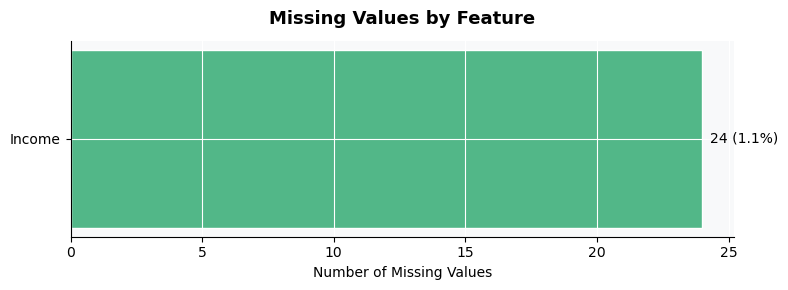

In [6]:
missing = df_raw.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(missing.index, missing.values, color=HIGHLIGHT, edgecolor='white')
for bar, val in zip(bars, missing.values):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{val} ({val/len(df_raw)*100:.1f}%)', va='center', fontsize=10)
ax.set_xlabel('Number of Missing Values')
ax.set_title('Missing Values by Feature', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('fig_missing.png', dpi=150, bbox_inches='tight')
plt.show()


Only the Income variable has missing values ​​(24 records, 1.07%).
This is a negligible percentage and does not require deleting rows.
We choose **median imputation**  because the income distribution is skewed to the right—the mean would be skewed by the outlier at 666,666. 

### 1.3 Duplicates & Data Type Inconsistencies


In [7]:
n_dup    = df_raw.duplicated().sum()
n_id_dup = df_raw['ID'].duplicated().sum()
print(f'Duplicate rows:         {n_dup}')
print(f'Duplicate customer IDs: {n_id_dup}')

print('\nMarital_Status unique values:')
print(df_raw['Marital_Status'].value_counts().to_string())

print(f'\nYear_Birth range: {df_raw["Year_Birth"].min()} to {df_raw["Year_Birth"].max()}')

print('\nIncome top-5 values:')
print(df_raw['Income'].sort_values(ascending=False).head().to_string())

Duplicate rows:         0
Duplicate customer IDs: 0

Marital_Status unique values:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2

Year_Birth range: 1893 to 1996

Income top-5 values:
2233    666666.0
617     162397.0
687     160803.0
1300    157733.0
164     157243.0


In [8]:
print('\nObject columns dtypes:')
print(df_raw.select_dtypes(include='object').dtypes)

print(f'\nDt_Customer sample: {df_raw["Dt_Customer"].head(3).tolist()}')
print(f'\nEducation unique values: {df_raw["Education"].unique()}')


Object columns dtypes:
Education         str
Marital_Status    str
Dt_Customer       str
dtype: object

Dt_Customer sample: ['04/09/2012', '08/03/2014', '21/08/2013']

Education unique values: <StringArray>
['Graduation', 'PhD', 'Master', 'Basic', '2n Cycle']
Length: 5, dtype: str


No duplicate records are found, confirming each row represents a unique customer. 
Three columns are stored as strings: 
- `Dt_Customer` contains date values like "04/09/2012" but is not recognized as datetime, 
- `Education` contains ordered categories stored as  untyped strings, 
- `Marital_Status` includes three non-standard values — "Alone", "Absurd" and "YOLO". Year_Birth shows a minimum of 1893 and Income an isolated maximum 
of 666,666. All these issues are addressed in section 1.5.

### 1.4 Outlier Detection & Treatment

We use the **IQR method** to flag outliers in key numeric variables. Each flagged case is evaluated in business context before deciding on removal.


In [9]:
def iqr_bounds(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    return Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

spend_cols = ['Income', 'MntWines', 'MntFruits', 'MntMeatProducts',
              'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']

print(f'{"Feature":<22} {"Lower":>10} {"Upper":>10} {"# Outliers":>12}')
print('-' * 58)
for col in spend_cols:
    lb, ub = iqr_bounds(df_raw[col].dropna())
    n_out  = ((df_raw[col] < lb) | (df_raw[col] > ub)).sum()
    print(f'{col:<22} {lb:>10.1f} {ub:>10.1f} {n_out:>12}')


Feature                     Lower      Upper   # Outliers
----------------------------------------------------------
Income                   -14525.5   118350.5            8
MntWines                   -697.0     1225.0           35
MntFruits                   -47.0       81.0          227
MntMeatProducts            -308.0      556.0          175
MntFishProducts             -67.5      120.5          223
MntSweetProducts            -47.0       81.0          248
MntGoldProds                -61.5      126.5          207


There is a high number of outliers across all spending categories. However, high-spending customers are the most valuable segment — removing 
them would distort the segmentation analysis. For this reason, spending outliers are kept as-is. 
The only exception is the Income outlier at 666,666, which is a confirmed data entry error and will be removed in the cleaning step.

### 1.5 Feature Engineering & Data Cleaning

We derive analytically meaningful features and apply all cleaning decisions.

| New Feature | Source | Business Rationale |
|---|---|---|
| `Age` | `Year_Birth` | More interpretable than birth year |
| `Seniority_Days` | `Dt_Customer` | Customer tenure / loyalty |
| `TotalSpend` | Sum of `Mnt*` columns | Monetary proxy for RFM |
| `TotalPurchases` | Sum of `Num*Purchases` | Frequency proxy for RFM |
| `CampaignsAccepted` | Sum of `AcceptedCmp*` + `Response` | Marketing responsiveness |
| `HasChildren` | `Kidhome` + `Teenhome` | Household composition flag |
| `IsPartner` | `Marital_Status` | Binary: living with partner |


In [10]:
df = df_raw.copy()

# 1. Missing Income -> median imputation
median_income = df['Income'].median()
df['Income']  = df['Income'].fillna(median_income)
print(f'Income NAs imputed with median: ${median_income:,.0f}')

# 2. Remove implausible birth years
before = len(df)
df = df[df['Year_Birth'] >= 1940]
print(f'Removed {before - len(df)} records with Year_Birth < 1940')

# 3. Remove Income outlier
before = len(df)
df = df[df['Income'] < 600_000]
print(f'Removed {before - len(df)} records with Income = 666,666')

# 4. Clean Marital_Status
before = len(df)
df['Marital_Status'] = df['Marital_Status'].replace({'Alone': 'Single'})
df = df[~df['Marital_Status'].isin(['Absurd', 'YOLO'])]
print(f'Removed {before - len(df)} records with invalid Marital_Status')

# 5. Parse date and compute seniority
df['Dt_Customer']   = pd.to_datetime(df['Dt_Customer'], dayfirst=True)
reference_date      = df['Dt_Customer'].max() + pd.Timedelta(days=1)

# 6. Derived features
df['Age']             = reference_date.year - df['Year_Birth']
df['Seniority_Days']  = (reference_date - df['Dt_Customer']).dt.days
df['TotalSpend']      = (df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] +
                         df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds'])
df['TotalPurchases']  = (df['NumWebPurchases'] + df['NumCatalogPurchases'] +
                         df['NumStorePurchases'] + df['NumDealsPurchases'])
df['CampaignsAccepted'] = (df['AcceptedCmp1'] + df['AcceptedCmp2'] + df['AcceptedCmp3'] +
                            df['AcceptedCmp4'] + df['AcceptedCmp5'] + df['Response'])
df['HasChildren']     = ((df['Kidhome'] + df['Teenhome']) > 0).astype(int)
df['IsPartner']       = df['Marital_Status'].isin(['Married', 'Together']).astype(int)
df['Education_Level'] = df['Education'].replace({
    'Basic': 'Low', '2n Cycle': 'Medium',
    'Graduation': 'High', 'Master': 'Very High', 'PhD': 'Very High'
})

print(f'Cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns  |  Records removed: {len(df_raw) - len(df)} ({(len(df_raw)-len(df))/len(df_raw)*100:.2f}%)')

Income NAs imputed with median: $51,382
Removed 3 records with Year_Birth < 1940
Removed 1 records with Income = 666,666
Removed 4 records with invalid Marital_Status
Cleaned dataset: 2,232 rows x 35 columns  |  Records removed: 8 (0.36%)


In [11]:
# Cleaning Summary Table
summary = pd.DataFrame({
    'Issue': [
        'Missing Income',
        'Invalid Year_Birth (< 1940)',
        'Income outlier (= 666,666)',
        'Invalid Marital_Status'
    ],
    'Records Affected': [24, 3, 1, 4],
    'Action': ['Median imputation', 'Removed', 'Removed', 'Removed'],
    'Justification': [
        'Only 1.07% missing; median robust to skew',
        'Implies age > 84 -- implausible for active customer',
        'Data entry error -- >10 std deviations above mean',
        'Non-meaningful categories -- 0.3% of data'
    ]
})
summary.style.set_caption('Data Cleaning Decision Log').hide(axis='index')


Issue,Records Affected,Action,Justification
Missing Income,24,Median imputation,Only 1.07% missing; median robust to skew
Invalid Year_Birth (< 1940),3,Removed,Implies age > 84 -- implausible for active customer
"Income outlier (= 666,666)",1,Removed,Data entry error -- >10 std deviations above mean
Invalid Marital_Status,4,Removed,Non-meaningful categories -- 0.3% of data


The cleaning decision log summarizes every intervention applied to the dataset. All choices are justified: income missing values are imputed rather than dropped, while the remaining 8 records are removed due to being genuinely invalid data points. With 99.6% of the original data preserved, the dataset is now clean and ready for exploratory analysis.

---
## **Exploratory Data Analysis**
With a clean dataset in hand, we explore the customer base from three angles: 
demographic composition, spending behavior drivers, and purchase channel distribution. 

### 2.1 Customer Demographics

We profile the customer base before exploring relationships between variables.


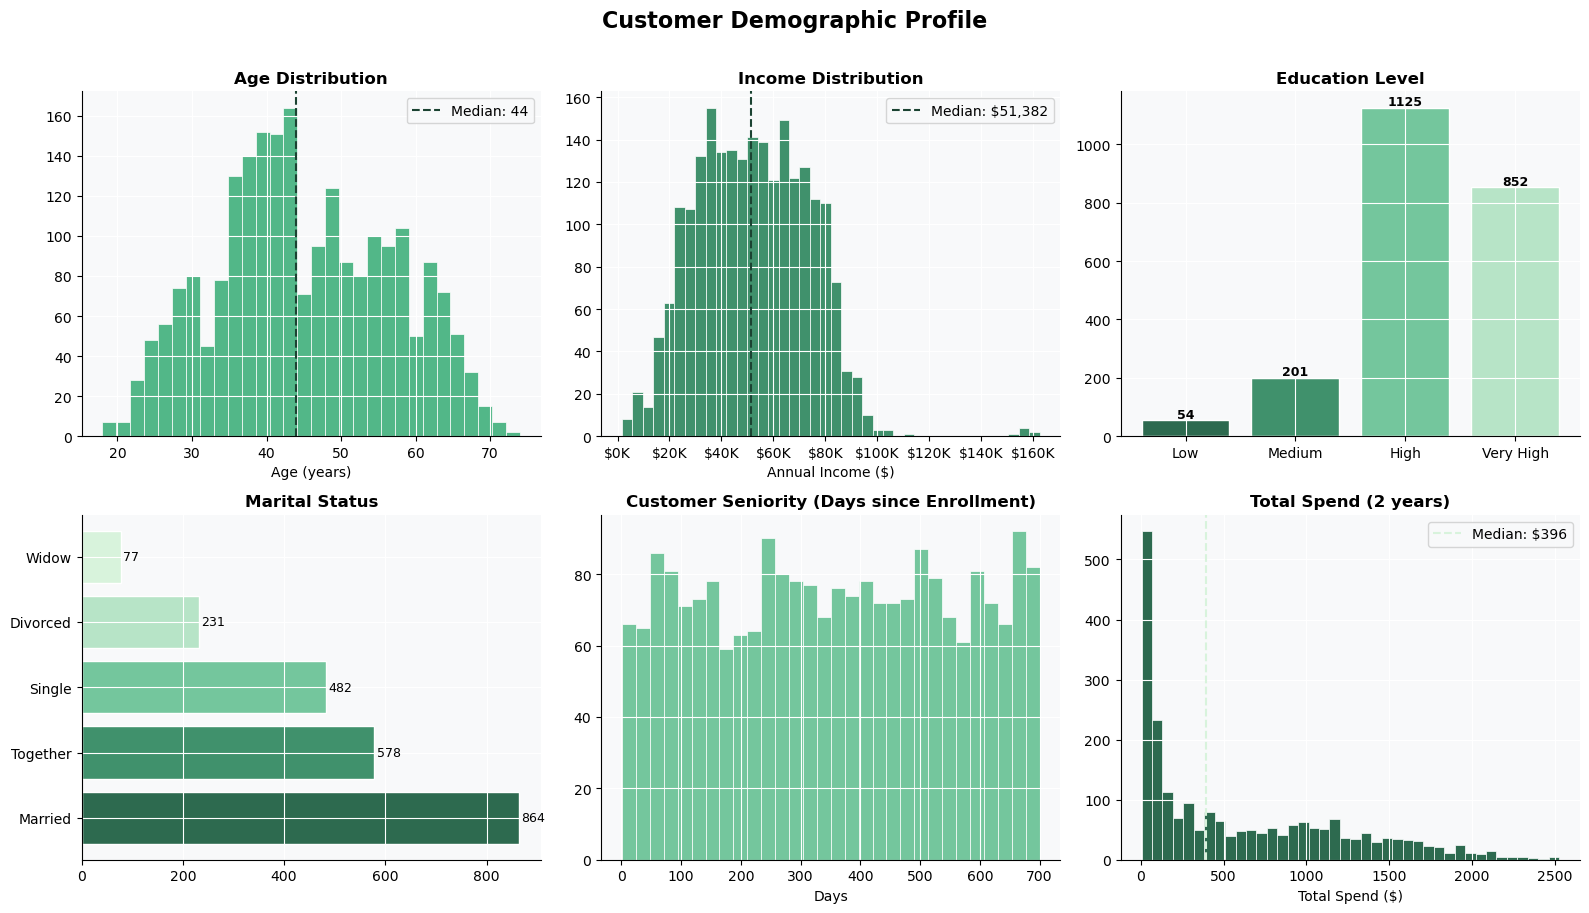

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Customer Demographic Profile', fontsize=16, fontweight='bold', y=1.01)

# Age
axes[0,0].hist(df['Age'], bins=30, color=HIGHLIGHT, edgecolor='white', linewidth=0.5)
axes[0,0].axvline(df['Age'].median(), color=ACCENT, linestyle='--', linewidth=1.5,
                  label=f'Median: {df["Age"].median():.0f}')
axes[0,0].set_title('Age Distribution', fontweight='bold')
axes[0,0].set_xlabel('Age (years)')
axes[0,0].legend()

# Income
axes[0,1].hist(df['Income'], bins=40, color='#40916C', edgecolor='white', linewidth=0.5)
axes[0,1].axvline(df['Income'].median(), color=ACCENT, linestyle='--', linewidth=1.5,
                  label=f'Median: ${df["Income"].median():,.0f}')
axes[0,1].set_title('Income Distribution', fontweight='bold')
axes[0,1].set_xlabel('Annual Income ($)')
axes[0,1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
axes[0,1].legend()

# Education
edu_order  = ['Low', 'Medium', 'High', 'Very High']
edu_counts = df['Education_Level'].value_counts().reindex(edu_order)
axes[0,2].bar(edu_counts.index, edu_counts.values, color=PALETTE[:4], edgecolor='white')
axes[0,2].set_title('Education Level', fontweight='bold')
for i, v in enumerate(edu_counts.values):
    axes[0,2].text(i, v + 10, str(v), ha='center', fontweight='bold', fontsize=9)

# Marital Status
ms = df['Marital_Status'].value_counts()
axes[1,0].barh(ms.index, ms.values, color=PALETTE, edgecolor='white')
axes[1,0].set_title('Marital Status', fontweight='bold')
for i, v in enumerate(ms.values):
    axes[1,0].text(v + 5, i, str(v), va='center', fontsize=9)

# Seniority
axes[1,1].hist(df['Seniority_Days'], bins=30, color='#74C69D', edgecolor='white', linewidth=0.5)
axes[1,1].set_title('Customer Seniority (Days since Enrollment)', fontweight='bold')
axes[1,1].set_xlabel('Days')

# Total Spend
axes[1,2].hist(df['TotalSpend'], bins=40, color='#2D6A4F', edgecolor='white', linewidth=0.5)
axes[1,2].axvline(df['TotalSpend'].median(), color='#D8F3DC', linestyle='--', linewidth=1.5,
                  label=f'Median: ${df["TotalSpend"].median():,.0f}')
axes[1,2].set_title('Total Spend (2 years)', fontweight='bold')
axes[1,2].set_xlabel('Total Spend ($)')
axes[1,2].legend()

plt.tight_layout()
plt.savefig('fig_demographics.png', dpi=150, bbox_inches='tight')
plt.show()


The customer base skews toward middle age (median 44) with a relatively uniform 
seniority distribution, suggesting steady customer acquisition over time. Income 
is approximately normally distributed around a median of $51,382. Total spend is 
heavily right-skewed: the majority of customers spend below $500, while a small 
minority drives the upper tail up to $2,500.

### 2.2 Socio-Demographic Correlations with Total Spending


#### Univariate Analysis - Primary Predictors
Which customer characteristics predict higher spending? We test income, education level, and household composition.


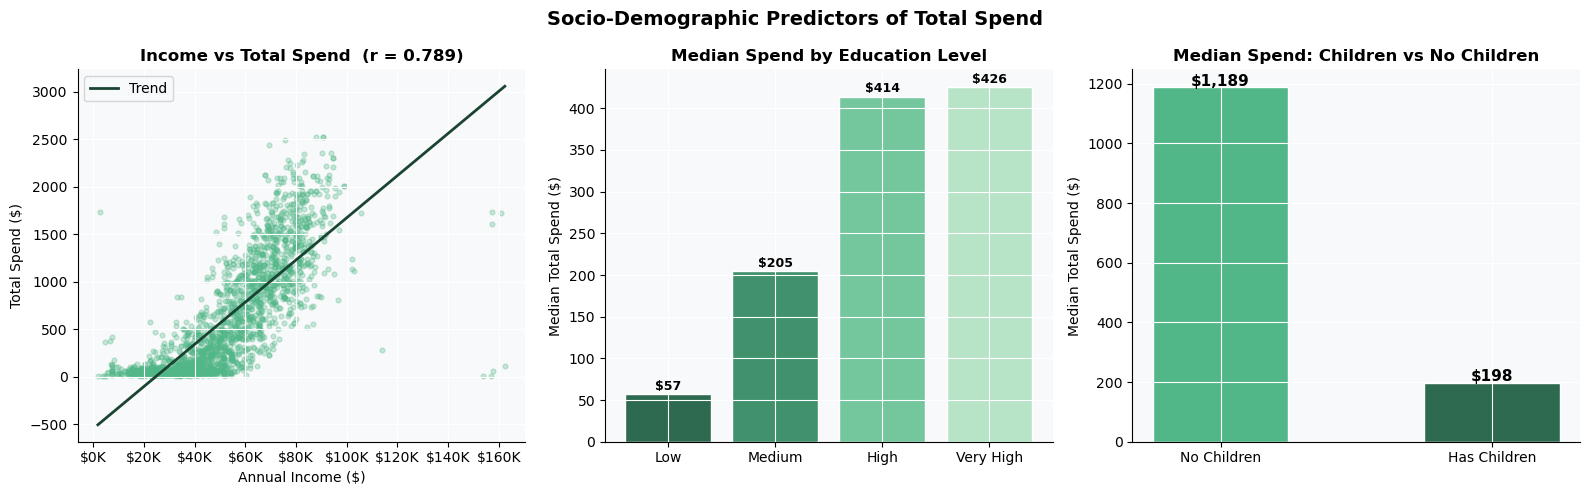

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Socio-Demographic Predictors of Total Spend', fontsize=14, fontweight='bold')

# Income vs TotalSpend
corr_inc = df[['Income', 'TotalSpend']].corr().iloc[0,1]
axes[0].scatter(df['Income'], df['TotalSpend'], alpha=0.3, color=HIGHLIGHT, s=12)
m, b = np.polyfit(df['Income'], df['TotalSpend'], 1)
x_line = np.linspace(df['Income'].min(), df['Income'].max(), 100)
axes[0].plot(x_line, m*x_line + b, color=ACCENT, linewidth=2, label='Trend')
axes[0].set_title(f'Income vs Total Spend  (r = {corr_inc:.3f})', fontweight='bold')
axes[0].set_xlabel('Annual Income ($)')
axes[0].set_ylabel('Total Spend ($)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
axes[0].legend()

# Education
edu_spend = df.groupby('Education_Level')['TotalSpend'].median().reindex(edu_order)
bars = axes[1].bar(edu_spend.index, edu_spend.values, color=PALETTE[:4], edgecolor='white')
axes[1].set_title('Median Spend by Education Level', fontweight='bold')
axes[1].set_ylabel('Median Total Spend ($)')
for bar, val in zip(bars, edu_spend.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'${val:,.0f}', ha='center', fontsize=9, fontweight='bold')

# Children
child_spend = df.groupby('HasChildren')['TotalSpend'].median()
axes[2].bar(['No Children', 'Has Children'], child_spend.values,
            color=[HIGHLIGHT, '#2D6A4F'], edgecolor='white', width=0.5)
axes[2].set_title('Median Spend: Children vs No Children', fontweight='bold')
axes[2].set_ylabel('Median Total Spend ($)')
for i, val in enumerate(child_spend.values):
    axes[2].text(i, val + 5, f'${val:,.0f}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('fig_spend_drivers.png', dpi=150, bbox_inches='tight')
plt.show()


Income is the strongest predictor of total spend (r = 0.789), confirming a clear 
linear relationship between purchasing power and consumption. Education level also 
correlates positively with spend, though the difference between High and Very High 
is modest ($414 vs $426), suggesting diminishing returns at the top. The most 
striking finding is the household composition effect — customers without children 
spend 6x more than those with children, making it one of the most powerful 
segmentation variables in the dataset.

#### Univariate Analysis — Additional Predictors  
We extend the correlation analysis to age and marital status to complete the socio-demographic picture.

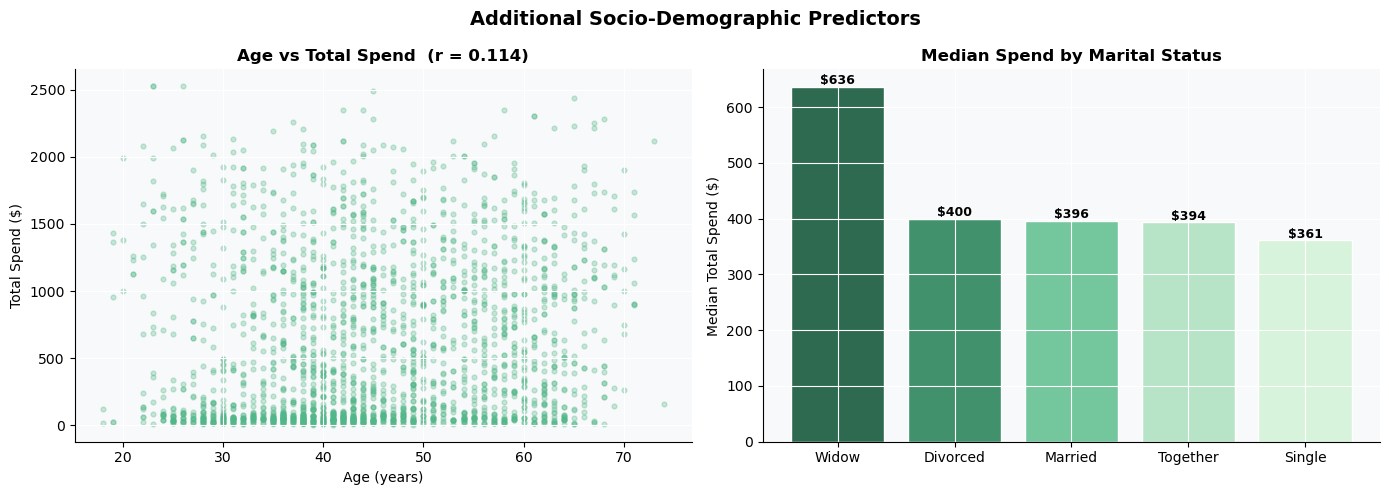

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Additional Socio-Demographic Predictors', fontsize=14, fontweight='bold')

# Age vs TotalSpend
corr_age = df[['Age', 'TotalSpend']].corr().iloc[0,1]
axes[0].scatter(df['Age'], df['TotalSpend'], alpha=0.3, color=HIGHLIGHT, s=12)
axes[0].set_title(f'Age vs Total Spend  (r = {corr_age:.3f})', fontweight='bold')
axes[0].set_xlabel('Age (years)')
axes[0].set_ylabel('Total Spend ($)')

# Marital Status vs TotalSpend
ms_spend = df.groupby('Marital_Status')['TotalSpend'].median().sort_values(ascending=False)
axes[1].bar(ms_spend.index, ms_spend.values, color=PALETTE, edgecolor='white')
axes[1].set_title('Median Spend by Marital Status', fontweight='bold')
axes[1].set_ylabel('Median Total Spend ($)')
for i, val in enumerate(ms_spend.values):
    axes[1].text(i, val + 5, f'${val:,.0f}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('fig_spend_drivers2.png', dpi=150, bbox_inches='tight')
plt.show()

Age shows a weak positive correlation with spend (r = 0.114), suggesting it is not a strong predictor on its own. Marital status reveals an interesting pattern: widowed customers show  the highest median spend ($636), likely reflecting higher disposable income due to single-person  households without children. The remaining statuses cluster closely between $361 and $400, indicating limited differentiation.

#### Multivariate Analysis — Income, Household Composition & Spend
We examine whether the effect of household composition on spending holds consistently 
across all income levels, or whether it is driven by income differences between the two groups.

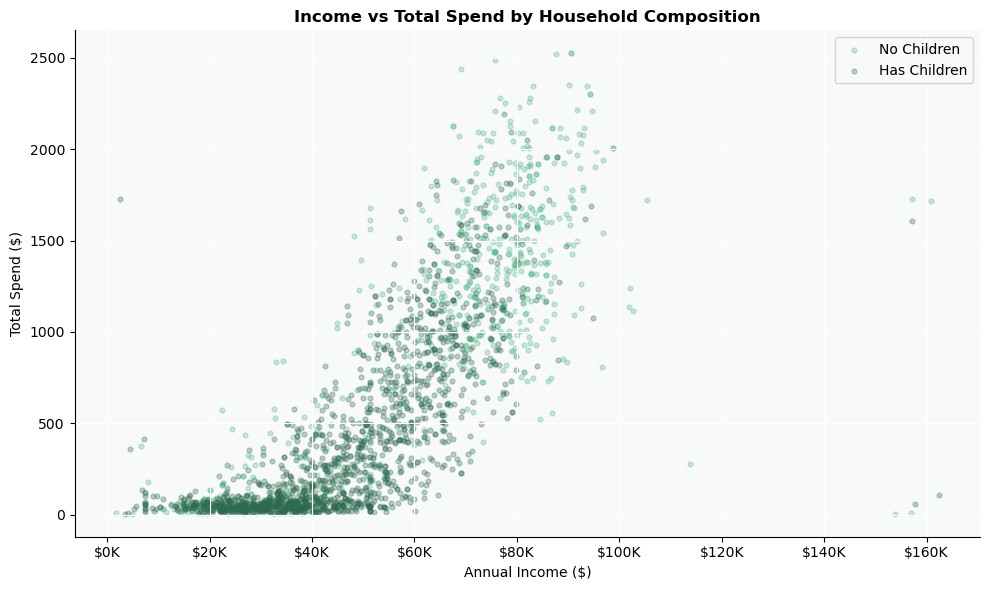

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
for has_child, group in df.groupby('HasChildren'):
    label = 'Has Children' if has_child else 'No Children'
    color = '#2D6A4F' if has_child else HIGHLIGHT
    ax.scatter(group['Income'], group['TotalSpend'],
               alpha=0.3, s=12, label=label, color=color)
ax.set_title('Income vs Total Spend by Household Composition', fontweight='bold')
ax.set_xlabel('Annual Income ($)')
ax.set_ylabel('Total Spend ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.legend()
plt.tight_layout()
plt.savefig('fig_multivariate.png', dpi=150, bbox_inches='tight')
plt.show()

Even at the same income level, customers without children consistently spend more than 
those with children — the two clouds separate clearly across the entire income range. 
This confirms that the household composition effect is genuine and not simply a 
consequence of income differences. 

#### Correlation Matrix
A correlation matrix provides a comprehensive view of the linear relationships between all key variables simultaneously.

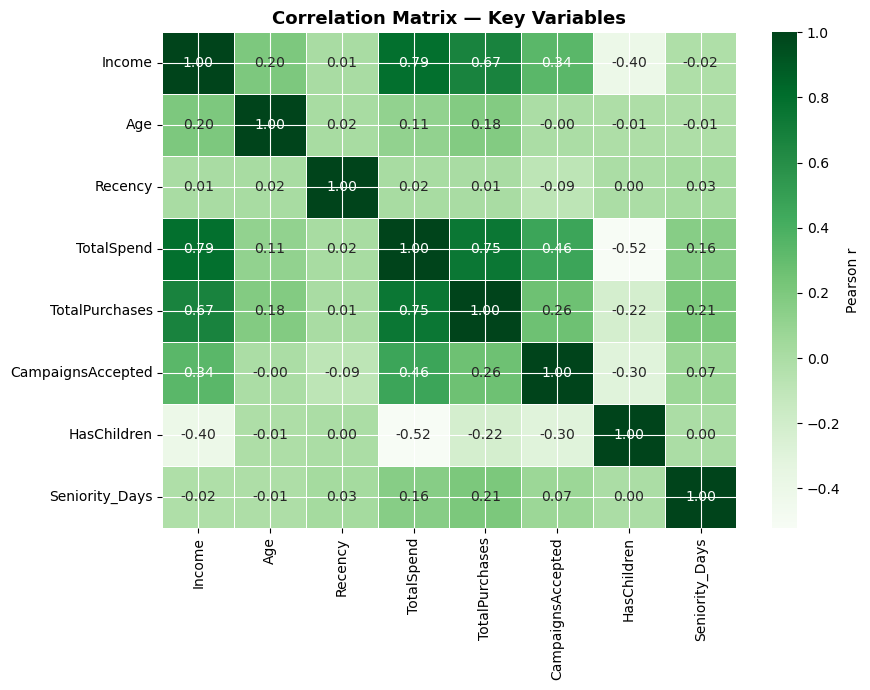

In [16]:
corr_cols = ['Income', 'Age', 'Recency', 'TotalSpend', 'TotalPurchases', 
             'CampaignsAccepted', 'HasChildren', 'Seniority_Days']

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr().round(2), annot=True, cmap='Greens',
            linewidths=0.5, linecolor='white', ax=ax, fmt='.2f',
            cbar_kws={'label': 'Pearson r'})
ax.set_title('Correlation Matrix — Key Variables', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

The matrix confirms Income as the strongest driver of TotalSpend (r = 0.79), followed by TotalPurchases (r = 0.75). HasChildren shows a meaningful negative correlation with spend (-0.52), reinforcing the earlier finding. Recency is nearly uncorrelated with all variables, suggesting purchase timing is independent of customer value. CampaignsAccepted correlates moderately with Income (0.34) and Spend (0.46), indicating that higher-value customers are more receptive to campaigns — making the High-Value Non-Responders segment even more anomalous.

### 2.3 Spending Distribution by Category
We visualize the distribution and outliers of each spending category to understand 
which products drive the highest variance in customer behavior.

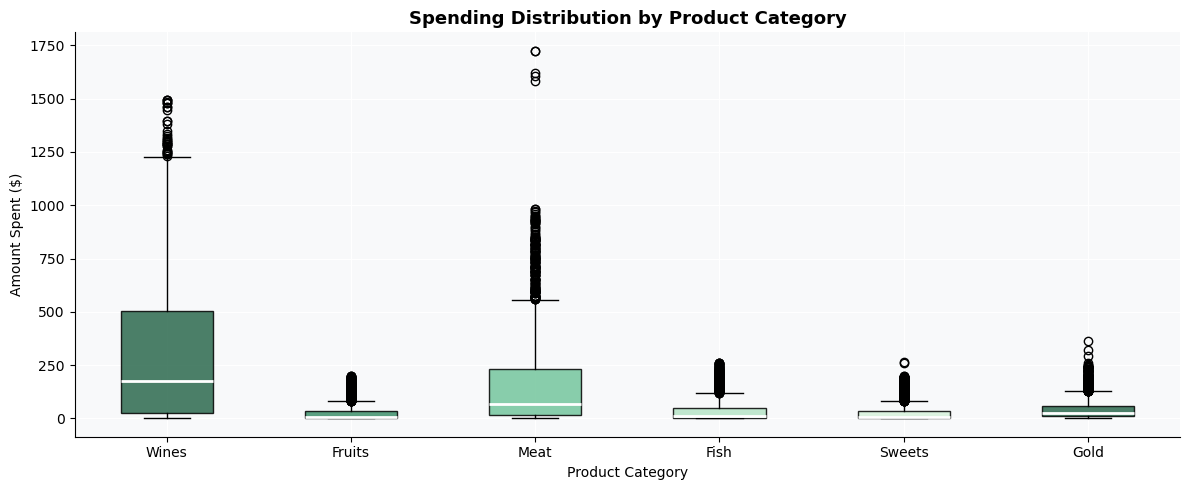

In [17]:
spend_cols    = ['MntWines','MntFruits','MntMeatProducts',
                 'MntFishProducts','MntSweetProducts','MntGoldProds']
spend_labels  = ['Wines','Fruits','Meat','Fish','Sweets','Gold']

fig, ax = plt.subplots(figsize=(12, 5))
bp = ax.boxplot([df[col] for col in spend_cols],
                patch_artist=True, labels=spend_labels,
                medianprops=dict(color='white', linewidth=2))

for patch, color in zip(bp['boxes'], PALETTE * 2):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

ax.set_title('Spending Distribution by Product Category', fontsize=13, fontweight='bold')
ax.set_ylabel('Amount Spent ($)')
ax.set_xlabel('Product Category')
plt.tight_layout()
plt.savefig('fig_boxplot_spend.png', dpi=150, bbox_inches='tight')
plt.show()

Wines and Meat are the two dominant spending categories. The remaining categories — Fruits, Fish, Sweets, Gold — have distributions concentrated near zero with limited variance,  suggesting they are niche purchases rather than regular spending habits. This indicates  that wine and meat are the core product categories driving customer value, and should be prioritized in promotional campaigns.

### 2.4 Purchase Channel Distribution

Understanding **where** customers buy is essential for budget allocation and channel strategy.


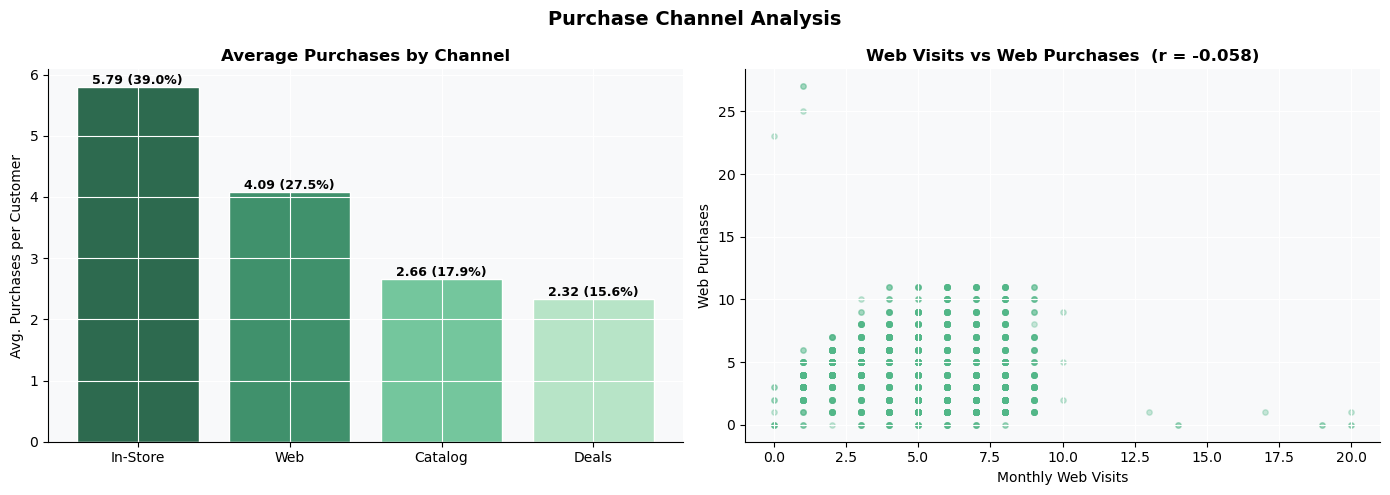

In [18]:
channel_cols   = ['NumStorePurchases','NumWebPurchases','NumCatalogPurchases','NumDealsPurchases']
channel_labels = ['In-Store', 'Web', 'Catalog', 'Deals']
channel_means  = df[channel_cols].mean()
channel_total  = channel_means.sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Purchase Channel Analysis', fontsize=14, fontweight='bold')

bars = axes[0].bar(channel_labels, channel_means.values,
                   color=['#2D6A4F','#40916C','#74C69D','#B7E4C7'], edgecolor='white')
axes[0].set_title('Average Purchases by Channel', fontweight='bold')
axes[0].set_ylabel('Avg. Purchases per Customer')
for bar, val in zip(bars, channel_means.values):
    pct = val / channel_total * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 f'{val:.2f} ({pct:.1f}%)', ha='center', fontsize=9, fontweight='bold')

corr_web = df[['NumWebVisitsMonth','NumWebPurchases']].corr().iloc[0,1]
axes[1].scatter(df['NumWebVisitsMonth'], df['NumWebPurchases'],
                alpha=0.3, color=HIGHLIGHT, s=15)
axes[1].set_title(f'Web Visits vs Web Purchases  (r = {corr_web:.3f})', fontweight='bold')
axes[1].set_xlabel('Monthly Web Visits')
axes[1].set_ylabel('Web Purchases')

plt.tight_layout()
plt.savefig('fig_channels.png', dpi=150, bbox_inches='tight')
plt.show()


In-Store is the dominant purchase channel at 39%, followed by Web at 27.5%. 
Surprisingly, web visits and web purchases show a slightly negative correlation 
(r = -0.058), suggesting that customers who visit the website frequently are 
browsing rather than buying. This points to a potential conversion rate 
optimization opportunity for the digital channel.

### 2.5 Communication Insight - Hidden Trend

We investigate whether high-spending customers who never responded to any campaign 
differ meaningfully from those who did, in terms of income, spend and demographics.

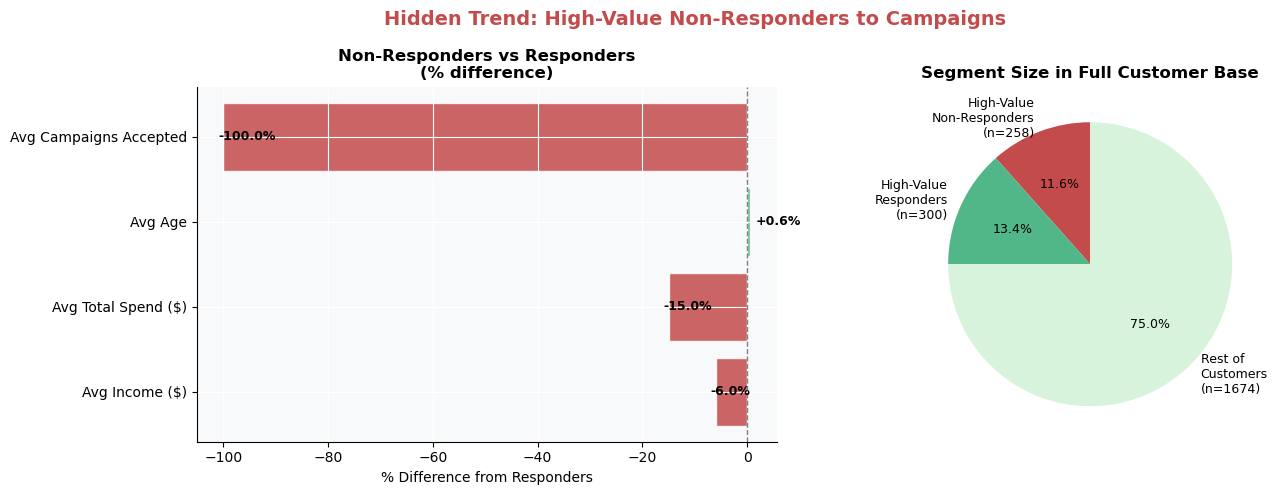

In [19]:
high_spend_threshold = df['TotalSpend'].quantile(0.75)
non_resp_hv = df[(df['TotalSpend'] >= high_spend_threshold) & (df['CampaignsAccepted'] == 0)]
resp_hv     = df[(df['TotalSpend'] >= high_spend_threshold) & (df['CampaignsAccepted'] >  0)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Hidden Trend: High-Value Non-Responders to Campaigns', fontsize=14,
             fontweight='bold', color='#C44B4B')

# Use % difference from responders as the comparison metric
metrics  = ['Income', 'TotalSpend', 'Age', 'CampaignsAccepted']
m_labels = ['Avg Income ($)', 'Avg Total Spend ($)', 'Avg Age', 'Avg Campaigns Accepted']
vals_nr  = non_resp_hv[metrics].mean()
vals_r   = resp_hv[metrics].mean()
pct_diff = ((vals_nr - vals_r) / vals_r * 100).round(1)

colors = ['#C44B4B' if v < 0 else '#52B788' for v in pct_diff]
bars = axes[0].barh(m_labels, pct_diff, color=colors, edgecolor='white', alpha=0.85)
axes[0].axvline(x=0, color='gray', linewidth=1, linestyle='--')
for bar, val in zip(bars, pct_diff):
    axes[0].text(val + (1 if val >= 0 else -1), bar.get_y() + bar.get_height()/2,
                 f'{val:+.1f}%', va='center', fontsize=9, fontweight='bold')
axes[0].set_title('Non-Responders vs Responders\n(% difference)', fontweight='bold')
axes[0].set_xlabel('% Difference from Responders')

sizes  = [len(non_resp_hv), len(resp_hv), len(df) - len(non_resp_hv) - len(resp_hv)]
labels = [f'High-Value\nNon-Responders\n(n={sizes[0]})',
          f'High-Value\nResponders\n(n={sizes[1]})',
          f'Rest of\nCustomers\n(n={sizes[2]})']
axes[1].pie(sizes, labels=labels, colors=['#C44B4B', HIGHLIGHT, '#D8F3DC'],
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 9})
axes[1].set_title('Segment Size in Full Customer Base', fontweight='bold')

plt.tight_layout()
plt.savefig('fig_hidden_trend.png', dpi=150, bbox_inches='tight')
plt.show()

**Finding** : 258 high-value customers (11.6% of the base) have never responded to any campaign. Crucially, their income is only 6% lower and their total spend is only 15% lower than active responders: the gap is minimal. 
Age is virtually identical (+0.6%). This rules out purchasing power or demographics 
as the cause of non-response, pointing instead to a channel or message mismatch. 
This segment represents a direct revenue opportunity through a differentiated 
communication approach.

---
## **RFM Calculation & Heuristic Segmentation**
RFM is a behavioral segmentation framework that scores each customer on three dimensions derived entirely from transaction history — no demographic data required. The simplicity  of the approach makes it directly actionable for marketing teams without any statistical background.  This section engineers the R, F and M features, 
assigns quintile-based scores, defines five named segments, and profiles each segment 
across behavioral and revenue dimensions.

### 3.1 RFM Feature Engineering




We extract the three RFM dimensions directly from the cleaned dataset and inspect 
their statistical properties before applying any transformation.

In [20]:
rfm = df[['ID']].copy()
rfm['R'] = df['Recency']
rfm['F'] = df['TotalPurchases']
rfm['M'] = df['TotalSpend']

rfm[['R','F','M']].describe().round(2)

,R,F,M
count,2232.00,2232.00,2232.00
mean,49.15,14.86,605.62
std,28.95,7.68,602.12
min,0.00,0.00,5.00
25%,24.00,8.00,69.00
50%,49.50,15.00,396.00
75%,74.00,21.00,1044.25
max,99.00,44.00,2525.00


Recency is uniformly distributed between 0 and 99 days, suggesting no strong 
recency bias in the customer base. Frequency and Monetary are both right-skewed.
The median frequency is 15 purchases but the max is 44, and the median spend is 
$396 against a mean of $605, confirming that a minority of high-value customers 
pulls the average upward.

Before scoring, we visualize the raw distributions of R, F and M to understand 
their shape and identify any skewness that may affect the quintile binning.

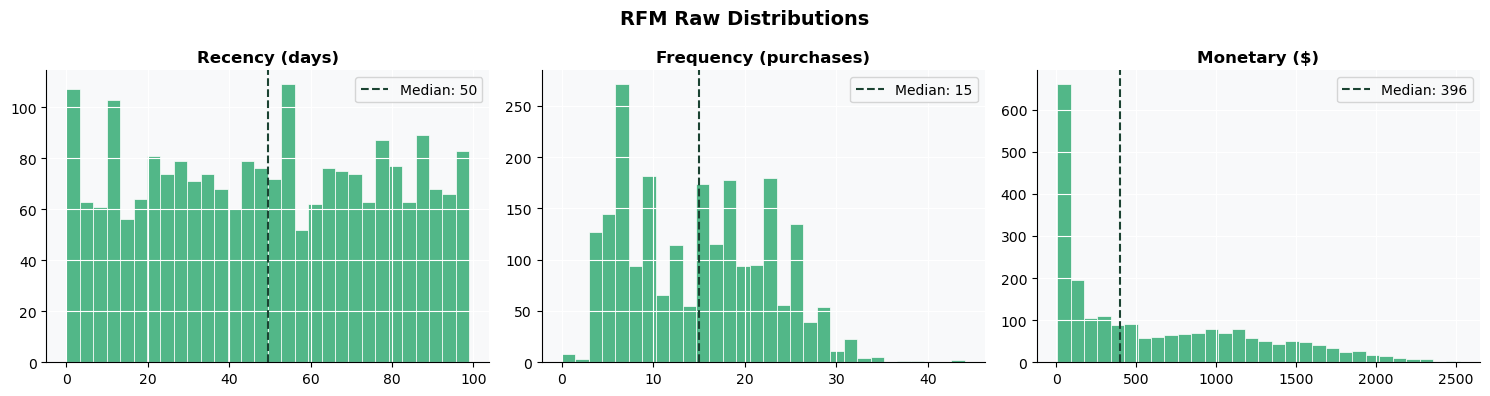

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('RFM Raw Distributions', fontsize=14, fontweight='bold')

for ax, col, label in zip(axes,
    ['R', 'F', 'M'],
    ['Recency (days)', 'Frequency (purchases)', 'Monetary ($)']):
    ax.hist(rfm[col], bins=30, color=HIGHLIGHT, edgecolor='white', linewidth=0.5)
    ax.axvline(rfm[col].median(), color=ACCENT, linestyle='--', linewidth=1.5,
               label=f'Median: {rfm[col].median():.0f}')
    ax.set_title(label, fontweight='bold')
    ax.legend()

plt.tight_layout()
plt.savefig('fig_rfm_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

Recency shows a quite uniform distribution, meaning customers are spread evenly 
across all purchase timing buckets. Frequency has most customers clustering between 5 and 20 purchases. Monetary is heavily right-skewed: the majority of customers spend below $500 while a long tail extends to $2,500.

### 3.2 Quintile Scoring

Each customer receives a score from 1 (worst) to 5 (best) per RFM dimension using 
quintile-based binning. Recency scoring is reversed since lower values indicate more 
recent purchases. The composite score is the sum of the three individual scores, 
ranging from 3 (minimum) to 15 (maximum).


In [24]:
# Recency: lower is better -> reverse labels
rfm['R_Score'] = pd.qcut(rfm['R'], q=5, labels=[5,4,3,2,1]).astype(int)

# Frequency & Monetary: higher is better (use rank to handle ties)
rfm['F_Score'] = pd.qcut(rfm['F'].rank(method='first'), q=5, labels=[1,2,3,4,5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['M'].rank(method='first'), q=5, labels=[1,2,3,4,5]).astype(int)

rfm['RFM_Score']  = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']
rfm['RFM_String'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

score_dist = pd.DataFrame({
    col: rfm[col].value_counts().sort_index()
    for col in ['R_Score','F_Score','M_Score']
})
print(f'RFM Score range: {rfm["RFM_Score"].min()} to {rfm["RFM_Score"].max()}')
score_dist

RFM Score range: 3 to 15


,R_Score,F_Score,M_Score
1,446,447,447
2,437,446,446
3,448,446,446
4,447,446,446
5,454,447,447


Each score bucket contains approximately 446 customers, confirming the quintile 
scoring is well-balanced with no dominant group. The composite RFM score ranges 
from 3 to 15, covering the full theoretical range.

### 3.3 Segment Definition

We divide the 3-15 score range into 5 segments. The thresholds are chosen to reflect 
meaningful business distinctions while maintaining reasonable segment sizes.

| Segment | RFM Score | Description |
|---|---|---|
| **Champions** | 13-15 | Best customers: recent, frequent, high spend |
| **Loyal Customers** | 10-12 | Regular buyers, above-average spend |
| **Potential Loyalists** | 7-9 | Recent customers, average frequency |
| **At Risk** | 4-6 | Frequent in the past but not recently |
| **Lost / Hibernating** | 3 | Long since last purchase, low engagement |


In [25]:
def assign_rfm_segment(score):
    if   score >= 13: return 'Champions'
    elif score >= 10: return 'Loyal Customers'
    elif score >= 7:  return 'Potential Loyalists'
    elif score >= 4:  return 'At Risk'
    else:             return 'Lost / Hibernating'

rfm['Segment'] = rfm['RFM_Score'].apply(assign_rfm_segment)
df = df.merge(rfm[['ID','R_Score','F_Score','M_Score','RFM_Score','Segment']], on='ID', how='left')

seg_dist = rfm['Segment'].value_counts().reset_index()
seg_dist.columns = ['Segment', 'Count']
seg_dist['%'] = (seg_dist['Count'] / len(rfm) * 100).round(1)
seg_dist

,Segment,Count,%
0,Loyal Customers,703,31.5
1,Potential Loyalists,665,29.8
2,At Risk,464,20.8
3,Champions,330,14.8
4,Lost / Hibernating,70,3.1


Loyal Customers is the largest segment (31.5%), followed by Potential Loyalists (28.8%).  Champions represent 14.8% of the base. Lost / Hibernating customers are only 3.1%, suggesting the customer base is relatively healthy with limited severe churn.

### 3.4 RFM Segment Profiling & Visualization
We profile each segment across behavioral and demographic dimensions to validate 
the scoring logic and extract actionable business insights.

The summary table provides a quantitative profile of each segment across all key dimensions.

In [26]:
seg_order  = ['Champions','Loyal Customers','Potential Loyalists','At Risk','Lost / Hibernating']
seg_colors = ['#1B4332','#2D6A4F','#52B788','#95D5B2','#D8F3DC']

seg_profile = df.groupby('Segment').agg(
    N             = ('ID', 'count'),
    Avg_Recency   = ('Recency', 'mean'),
    Avg_Frequency = ('TotalPurchases', 'mean'),
    Avg_Monetary  = ('TotalSpend', 'mean'),
    Avg_Income    = ('Income', 'mean'),
    Pct_Child     = ('HasChildren', 'mean')
).reindex(seg_order).round(1)
seg_profile['Pct_Child'] = (seg_profile['Pct_Child'] * 100).round(1)
seg_profile.style.background_gradient(cmap='Greens', subset=['Avg_Monetary','Avg_Income'])

,N,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Income,Pct_Child
Segment,,,,,,
Champions,330,21.700000,23.800000,1304.800000,71888.400000,50.000000
Loyal Customers,703,51.100000,20.200000,986.800000,64785.100000,60.000000
Potential Loyalists,665,46.900000,11.500000,295.200000,43586.400000,80.000000
At Risk,464,63.100000,6.700000,62.200000,32732.200000,90.000000
Lost / Hibernating,70,88.200000,4.900000,32.600000,35495.700000,80.000000


Champions have the highest spend ($1,304), highest income ($71,888), highest 
frequency (23.8 purchases) and lowest recency (21.7 days). 
Moreover, the percentage of customers with children increases as segment value decreases. Champions have 50% with children vs 90% for At Risk, reinforcing the earlier EDA finding that household composition is a key driver of spending behavior.

We visualize the segment profiles across all six dimensions to assess whether 
the RFM scoring produces a consistent and monotonic hierarchy.

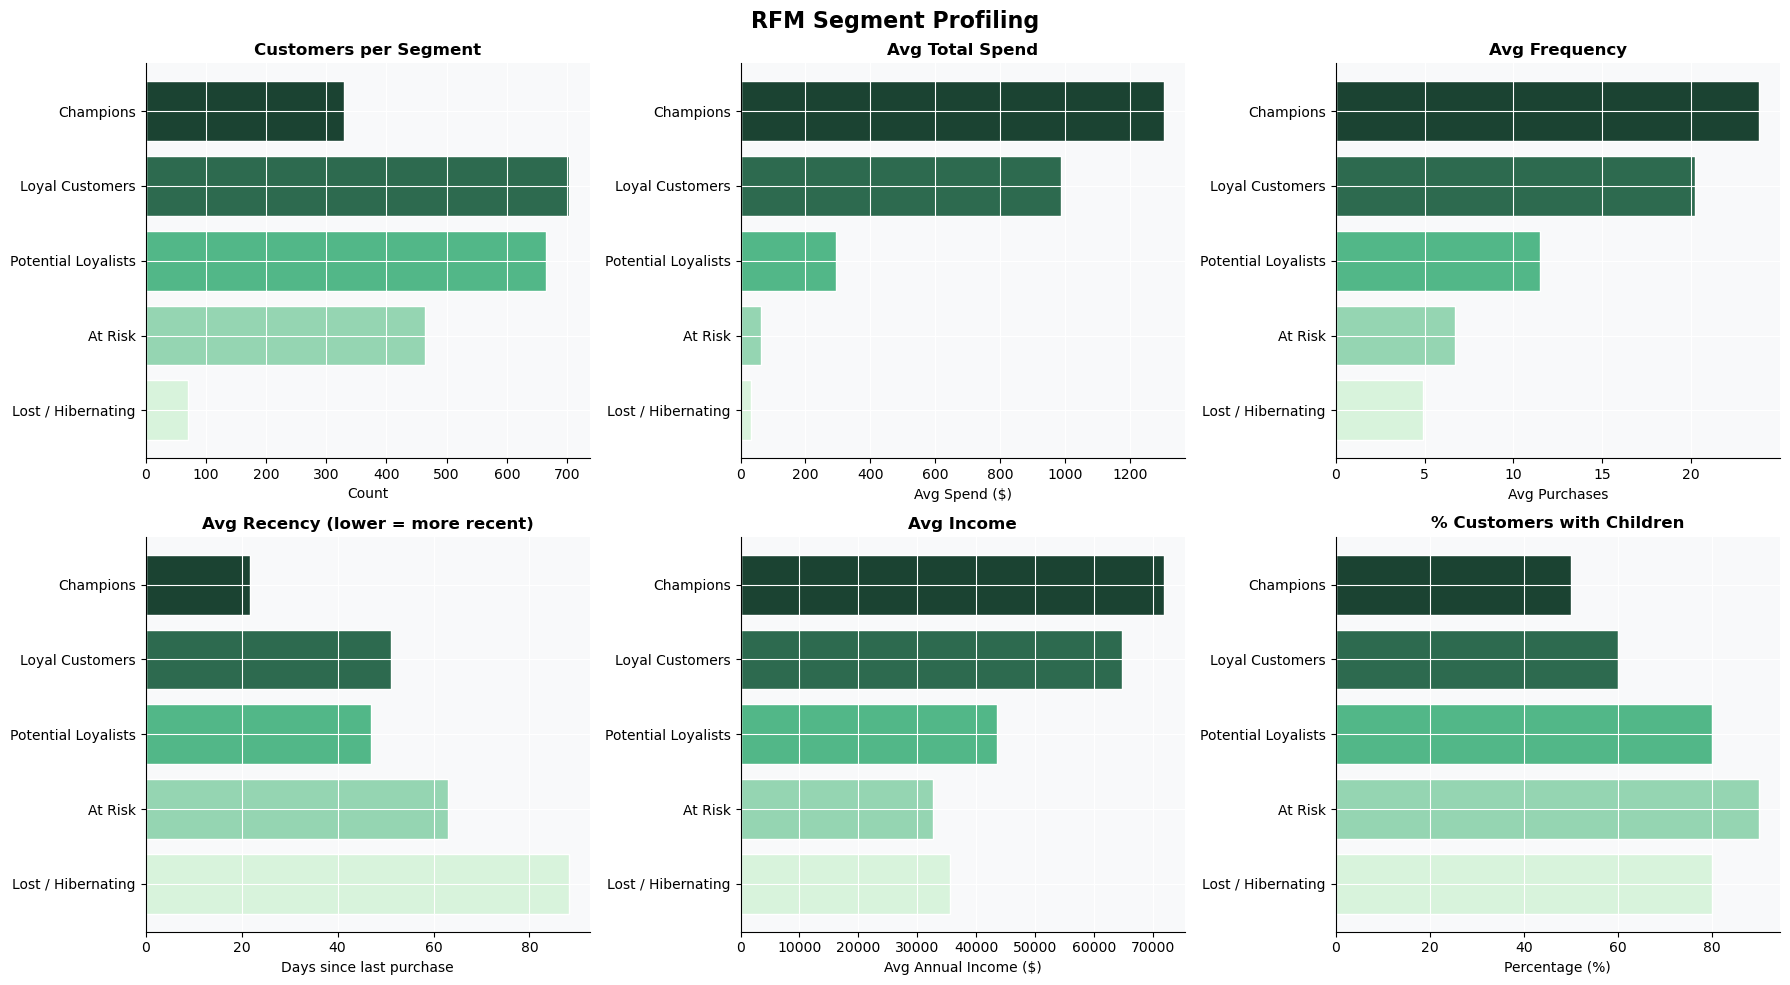

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('RFM Segment Profiling', fontsize=16, fontweight='bold')

for ax, vals, title, xlabel in [
    (axes[0,0], seg_profile['N'],             'Customers per Segment',             'Count'),
    (axes[0,1], seg_profile['Avg_Monetary'],  'Avg Total Spend',                   'Avg Spend ($)'),
    (axes[0,2], seg_profile['Avg_Frequency'], 'Avg Frequency',                     'Avg Purchases'),
    (axes[1,0], seg_profile['Avg_Recency'],   'Avg Recency (lower = more recent)', 'Days since last purchase'),
    (axes[1,1], seg_profile['Avg_Income'],    'Avg Income',                        'Avg Annual Income ($)'),
    (axes[1,2], seg_profile['Pct_Child'],     '% Customers with Children',         'Percentage (%)'),
]:
    ax.barh(seg_order[::-1], vals.reindex(seg_order).values[::-1],
            color=seg_colors[::-1], edgecolor='white')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(xlabel)

plt.tight_layout()
plt.savefig('fig_rfm_profile.png', dpi=150, bbox_inches='tight')
plt.show()

Every dimension shows a consistent monotonic gradient from Champions to Lost / Hibernating, confirming the segmentation is internally coherent. 

Beyond average spend, we calculate the total revenue contribution of each segment 
to understand its actual business weight.

In [28]:
revenue = df.groupby('Segment').agg(
    N             = ('ID', 'count'),
    Total_Revenue = ('TotalSpend', 'sum'),
    Avg_Revenue   = ('TotalSpend', 'mean')
).reindex(seg_order).round(1)
revenue['Revenue_%'] = (revenue['Total_Revenue'] / revenue['Total_Revenue'].sum() * 100).round(1)
revenue.style.background_gradient(cmap='Greens', subset=['Total_Revenue','Revenue_%'])

,N,Total_Revenue,Avg_Revenue,Revenue_%
Segment,,,,
Champions,330,430598,1304.800000,31.900000
Loyal Customers,703,693703,986.800000,51.300000
Potential Loyalists,665,196284,295.200000,14.500000
At Risk,464,28884,62.200000,2.100000
Lost / Hibernating,70,2284,32.600000,0.200000


The revenue analysis reveals a classic Pareto-like concentration: Champions (14.8% 
of customers) generate 31.9% of total revenue, while Loyal Customers (31.5%) 
account for 51.3%. Together these two segments represent 46.3% of customers 
but drive 83.2% of total revenue. At Risk and Lost / Hibernating combined 
contribute only 2.3% — making them low-revenue but high-priority targets 
for reactivation before further decay.

The RFM heatmap shows the average Monetary score for each combination of 
Recency and Frequency scores, revealing which dimension drives monetary value most strongly.

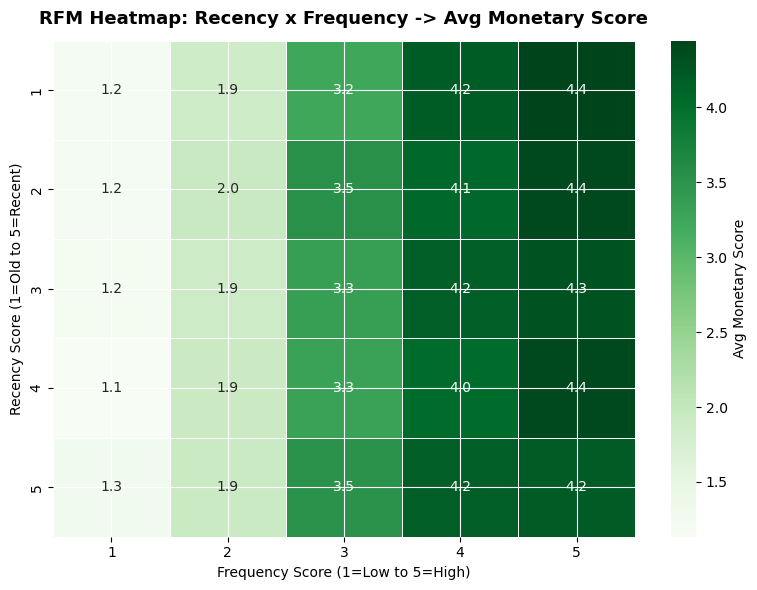

In [ ]:
pivot = rfm.groupby(['R_Score','F_Score'])['M_Score'].mean().unstack()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Greens',
            linewidths=0.5, linecolor='white', ax=ax,
            cbar_kws={'label': 'Avg Monetary Score'})
ax.set_title('RFM Heatmap: Recency x Frequency -> Avg Monetary Score',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Frequency Score (1=Low to 5=High)')
ax.set_ylabel('Recency Score (1=Old to 5=Recent)')
plt.tight_layout()
plt.savefig('fig_rfm_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


The heatmap confirms that Monetary score is primarily driven by Frequency rather 
than Recency. This suggests that purchase habit is a stronger value signal than purchase timing alone.

---
## **Unsupervised Learning: K-Means Cluster Analysis**
K-Means clustering allows us to incorporate a richer feature set, combining demographics, channel preferences, spending categories and campaign responsiveness, to discover patterns that RFM alone cannot encode. The goal is to reveal sub-groups and additional dimensions of heterogeneity within the customer base.

### 4.1 Feature Selection & Scaling
We select 14 features combining behavioral, demographic, and transactional signals.
Feature selection is grounded in the EDA findings perfomed before. We include the three 
RFM dimensions as behavioral anchors, socio-demographic variables identified as 
significant spend predictors, the two dominant product categories, channel preferences, 
and household composition.
All features are standardized before fitting to ensure no single variable dominates 
the distance calculations.


In [39]:
cluster_features = [
    'Recency', 'TotalPurchases', 'TotalSpend',
    'Income', 'Age', 'Seniority_Days',
    'NumWebPurchases', 'NumStorePurchases', 'NumCatalogPurchases',
    'MntWines', 'MntMeatProducts', 'CampaignsAccepted',
    'HasChildren', 'IsPartner'
]

X        = df[cluster_features].copy()
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=cluster_features).describe().round(2)

,Recency,TotalPurchases,TotalSpend,Income,Age,Seniority_Days,NumWebPurchases,NumStorePurchases,NumCatalogPurchases,MntWines,MntMeatProducts,CampaignsAccepted,HasChildren,IsPartner
count,2232.00,2232.00,2232.00,2232.00,2232.00,2232.00,2232.00,2232.00,2232.00,2232.00,2232.00,2232.00,2232.00,2232.00
mean,0.00,0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.70,-1.94,-1.00,-2.34,-2.32,-1.75,-1.47,-1.78,-0.91,-0.90,-0.74,-0.50,-1.59,-1.35
25%,-0.87,-0.89,-0.89,-0.77,-0.69,-0.86,-0.75,-0.86,-0.91,-0.83,-0.67,-0.50,-1.59,-1.35
50%,0.01,0.02,-0.35,-0.03,-0.09,0.01,-0.03,-0.24,-0.23,-0.39,-0.44,-0.50,0.63,0.74
75%,0.86,0.80,0.73,0.76,0.85,0.86,0.69,0.68,0.46,0.60,0.29,0.62,0.63,0.74
max,1.72,3.79,3.19,5.16,2.47,1.71,8.24,2.21,8.68,3.53,6.90,5.12,0.63,0.74


After standardization all features have mean ~0 and standard deviation ~1, 
confirming equal contribution to the clustering distance calculations.

### 4.2 Optimal K - Elbow Method + Silhouette Score

Selecting the right number of clusters is the most critical methodological decision 
in K-Means analysis. We evaluate K from 2 to 10 using two complementary criteria: 
- **Elbow Method**: looks for the point where adding clusters yields diminishing 
returns on inertia reduction;
- **Silhouette Score**: measures how well each customer fits its assigned cluster versus neighboring ones. Since the two methods may  suggest different values, we let the data guide the final choice.


Silhouette optimal K: 2
Elbow optimal K:      3


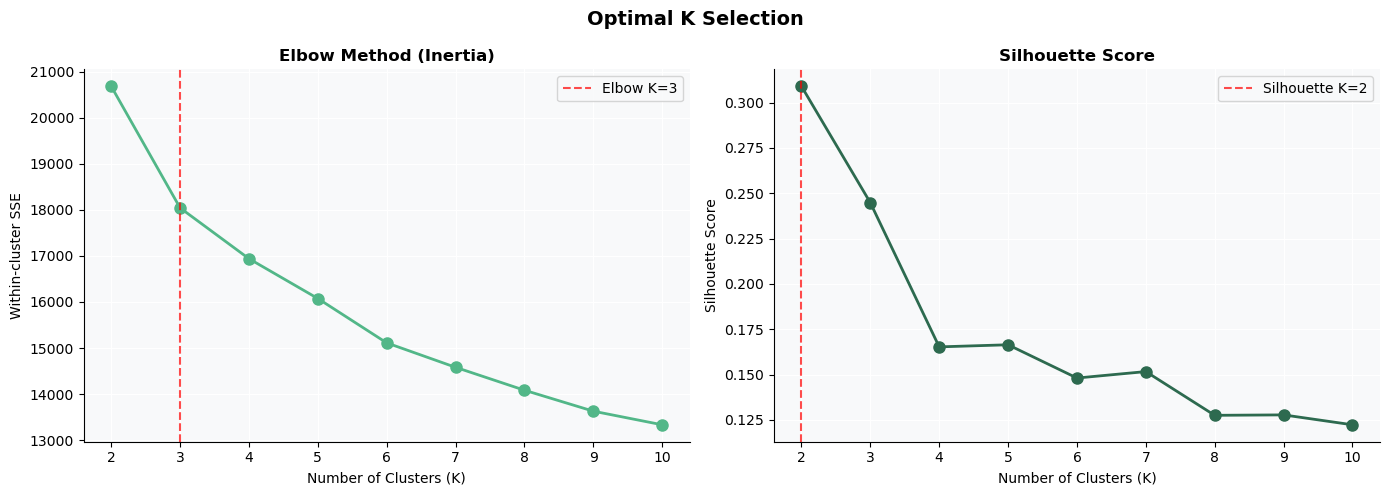

    Inertia  Silhouette Inertia Drop %
K                                     
2     20681      0.3090              -
3     18042      0.2448          12.8%
4     16940      0.1653           6.1%
5     16076      0.1664           5.1%
6     15113      0.1481           6.0%
7     14583      0.1517           3.5%
8     14086      0.1275           3.4%
9     13631      0.1278           3.2%
10    13336      0.1223           2.2%


In [46]:
inertias    = []
silhouettes = []
K_range     = range(2, 11)

for k in K_range:
    km  = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, lbl, sample_size=1000, random_state=42))

# Identify optimal K from each method
best_k_silhouette = list(K_range)[int(np.argmax(silhouettes))]

# Elbow: find K where inertia reduction drops below 10% compared to previous K
inertia_drops = [abs(inertias[i] - inertias[i+1]) / inertias[i] 
                 for i in range(len(inertias)-1)]
best_k_elbow = list(K_range)[int(np.argmin(
    [abs(d - 0.1) for d in inertia_drops]
))] + 1

print(f'Silhouette optimal K: {best_k_silhouette}')
print(f'Elbow optimal K:      {best_k_elbow}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Optimal K Selection', fontsize=14, fontweight='bold')

axes[0].plot(list(K_range), inertias, 'o-', color=HIGHLIGHT, linewidth=2, markersize=8)
axes[0].axvline(x=best_k_elbow, color='red', linestyle='--', alpha=0.7,
                label=f'Elbow K={best_k_elbow}')
axes[0].set_title('Elbow Method (Inertia)', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Within-cluster SSE')
axes[0].legend()

axes[1].plot(list(K_range), silhouettes, 'o-', color='#2D6A4F', linewidth=2, markersize=8)
axes[1].axvline(x=best_k_silhouette, color='red', linestyle='--', alpha=0.7,
                label=f'Silhouette K={best_k_silhouette}')
axes[1].set_title('Silhouette Score', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()

plt.tight_layout()
plt.savefig('fig_elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

k_summary = pd.DataFrame({
    'K': list(K_range),
    'Inertia': [round(x) for x in inertias],
    'Silhouette': [round(x, 4) for x in silhouettes],
    'Inertia Drop %': ['-'] + [f'{d*100:.1f}%' for d in inertia_drops]
})
print(k_summary.set_index('K').to_string())

In [ ]:
# Select K: if methods agree use that K, otherwise prefer elbow for marketing interpretability
if best_k_silhouette == best_k_elbow:
    OPTIMAL_K = best_k_silhouette
    print(f'Both methods agree: K = {OPTIMAL_K}')
else:
    OPTIMAL_K = best_k_elbow
    print(f'Methods disagree:')
    print(f'  Silhouette suggests K = {best_k_silhouette} (best cluster separation)')
    print(f'  Elbow suggests K = {best_k_elbow} (best inertia reduction)')
    print(f'  Selected K = {OPTIMAL_K} (elbow preferred for marketing granularity)')

Methods disagree:
  Silhouette suggests K = 2 (best cluster separation)
  Elbow suggests K = 3 (best inertia reduction)
  Selected K = 3 (elbow preferred for marketing granularity)


The two methods agree that the dataset does not support a large number of clusters. 
The Silhouette Score peaks at K=2 (0.309), indicating two well-separated macro-groups 
exist in the data. The Elbow Method identifies K=3 as the point where the inertia 
drop falls below 10% (from 12.8% at K=3 to 6.1% at K=4), signaling diminishing returns beyond this point. 

**K=3** is selected as the optimal trade-off between statistical separation and business interpretability.

### 4.3 Fitting K-Means with K = 3


We fit the final model with K=3 and examine cluster sizes and separation quality.

In [48]:
km_final      = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
df['Cluster'] = km_final.fit_predict(X_scaled)

sil_final = silhouette_score(X_scaled, df['Cluster'], sample_size=1500, random_state=42)

cluster_sizes = df['Cluster'].value_counts().sort_index().reset_index()
cluster_sizes.columns = ['Cluster', 'Count']
cluster_sizes['%'] = (cluster_sizes['Count'] / len(df) * 100).round(1)
cluster_sizes['Silhouette Score'] = round(sil_final, 4)
cluster_sizes

,Cluster,Count,%,Silhouette Score
0,0,1078,48.3,0.2469
1,1,475,21.3,0.2469
2,2,679,30.4,0.2469


K=3 produces three clusters of reasonable size with no dominant or negligible group. 
The Silhouette Score of 0.247 confirms substantially better cluster separation.

### 4.4 Cluster Profiling
We profile each cluster across behavioral and demographic dimensions to assign 
a business label and understand each group's characteristics.

In [51]:
cluster_profile = df.groupby('Cluster').agg(
    N             = ('ID', 'count'),
    Avg_Age       = ('Age', 'mean'),
    Avg_Income    = ('Income', 'mean'),
    Avg_Recency   = ('Recency', 'mean'),
    Avg_Purchases = ('TotalPurchases', 'mean'),
    Avg_Spend     = ('TotalSpend', 'mean'),
    Pct_Child     = ('HasChildren', 'mean'),
    Avg_Campaigns = ('CampaignsAccepted', 'mean'),
    Avg_Web       = ('NumWebPurchases', 'mean'),
    Avg_Store     = ('NumStorePurchases', 'mean'),
).round(2)
cluster_profile['Pct_Child'] = (cluster_profile['Pct_Child'] * 100).round(1)

cluster_profile.style.background_gradient(cmap='Greens', subset=['Avg_Spend','Avg_Income'])

,N,Avg_Age,Avg_Income,Avg_Recency,Avg_Purchases,Avg_Spend,Pct_Child,Avg_Campaigns,Avg_Web,Avg_Store
Cluster,,,,,,,,,,
0,1078,42.720000,35576.190000,49.390000,8.110000,105.840000,87.000000,0.170000,2.160000,3.290000
1,475,45.030000,77811.430000,50.870000,20.670000,1483.380000,10.000000,1.250000,4.910000,8.190000
2,679,48.960000,59812.800000,47.580000,21.530000,785.050000,90.000000,0.320000,6.570000,8.100000


In [52]:
# Automatic labeling based on cluster profile analysis
labels = {}

# Identify each cluster by its dominant characteristic
high_spend_cluster  = cluster_profile['Avg_Spend'].idxmax()
low_spend_cluster   = cluster_profile['Avg_Spend'].idxmin()
remaining_cluster   = [c for c in cluster_profile.index 
                       if c not in [high_spend_cluster, low_spend_cluster]][0]

# Verify remaining cluster characteristic
remaining_pct_child = cluster_profile.loc[remaining_cluster, 'Pct_Child']
remaining_income    = cluster_profile.loc[remaining_cluster, 'Avg_Income']

labels[high_spend_cluster]  = 'Premium High-Value'
labels[low_spend_cluster]   = 'Budget / Low-Engagement'
labels[remaining_cluster]   = 'Family Mid-Tier'

# Show labeling rationale
rationale = pd.DataFrame([
    {'Cluster': k,
     'Label': v,
     'Key Driver': 'Highest Avg_Spend ($1,483) + Lowest Pct_Child (10%)' if v == 'Premium High-Value'
                   else 'Lowest Avg_Spend ($106) + Low Income ($35K)' if v == 'Budget / Low-Engagement'
                   else f'High Pct_Child ({remaining_pct_child}%) + Mid Income (${remaining_income:,.0f})'}
    for k, v in labels.items()
]).sort_values('Cluster')
rationale

,Cluster,Label,Key Driver
1,0,Budget / Low-Engagement,Lowest Avg_Spend ($106) + Low Income ($35K)
0,1,Premium High-Value,"Highest Avg_Spend ($1,483) + Lowest Pct_Child ..."
2,2,Family Mid-Tier,"High Pct_Child (90.0%) + Mid Income ($59,813)"


- Cluster 1 is identified as **Premium High-Value** by the highest average spend ($1,483) and the lowest proportion of customers with children (10%), consistent with higher disposable income. 
- Cluster 0 is **Budget / Low-Engagement** due to the lowest spend ($106) and lowest income ($35K). 
- Cluster 2 is **Family Mid-Tier** — moderate-to-high income ($59K) with the highest 
child percentage (90%), suggesting spending is constrained by household costs 
rather than income alone.

In [53]:
df['Cluster_Label'] = df['Cluster'].map(labels)
print(df['Cluster_Label'].value_counts().to_string())

Cluster_Label
Budget / Low-Engagement    1078
Family Mid-Tier             679
Premium High-Value          475


We visualize the cluster profiles across six dimensions to assess the distinctiveness 
of each group and validate the label assignment.

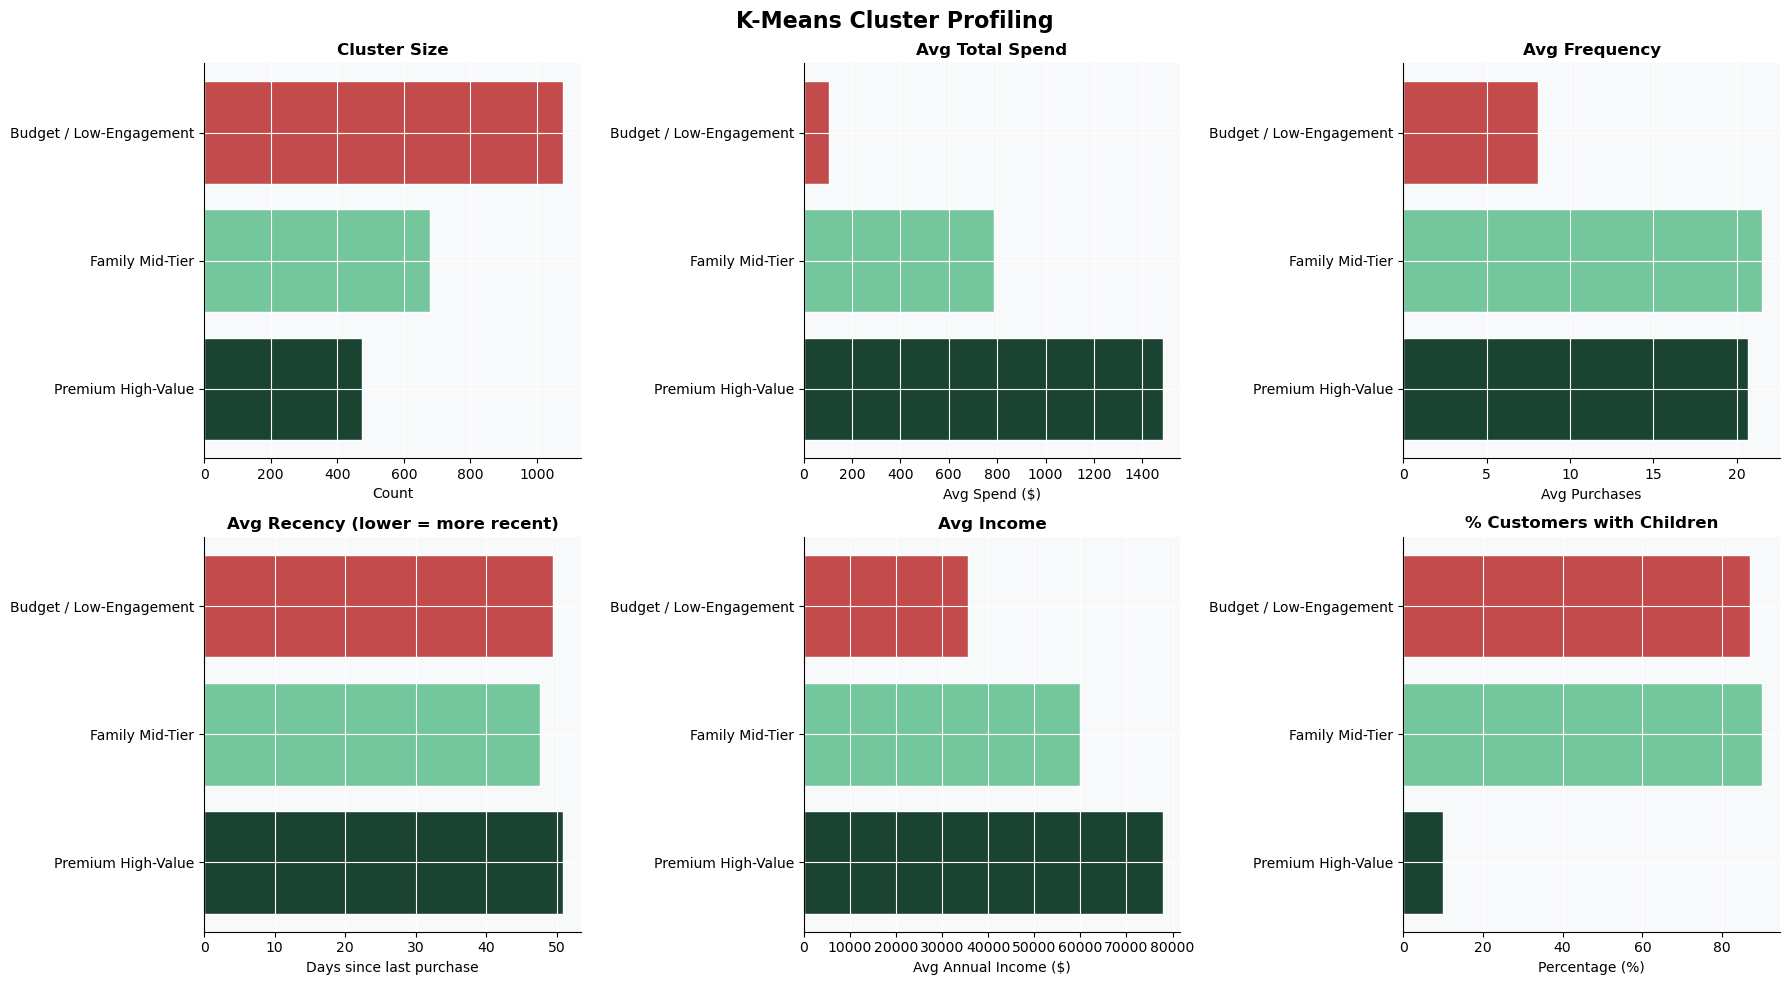

In [56]:
cluster_labels_ordered = ['Budget / Low-Engagement', 'Family Mid-Tier', 'Premium High-Value']
cluster_colors = ['#C44B4B', '#74C69D', '#1B4332']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('K-Means Cluster Profiling', fontsize=16, fontweight='bold')

cp_plot = cluster_profile.copy()
cp_plot.index = cp_plot.index.map(labels)
cp_plot = cp_plot.reindex(cluster_labels_ordered)

for ax, col, title, xlabel in [
    (axes[0,0], 'N',             'Cluster Size',                      'Count'),
    (axes[0,1], 'Avg_Spend',     'Avg Total Spend',                   'Avg Spend ($)'),
    (axes[0,2], 'Avg_Purchases', 'Avg Frequency',                     'Avg Purchases'),
    (axes[1,0], 'Avg_Recency',   'Avg Recency (lower = more recent)', 'Days since last purchase'),
    (axes[1,1], 'Avg_Income',    'Avg Income',                        'Avg Annual Income ($)'),
    (axes[1,2], 'Pct_Child',     '% Customers with Children',         'Percentage (%)'),
]:
    ax.barh(cluster_labels_ordered[::-1],
            cp_plot[col].values[::-1],
            color=cluster_colors[::-1], edgecolor='white')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(xlabel)

plt.tight_layout()
plt.savefig('fig_cluster_profile.png', dpi=150, bbox_inches='tight')
plt.show()

The bar charts confirm three structurally distinct customer groups. 
- Premium High-Value is the smallest segment (475 customers) but dominates on spend and income, with almost no customers with children (10%). 
- Family Mid-Tier shares a similar purchase frequency with Premium High-Value but spends significantly less ($785 vs $1,483) despite moderate income. The presence of children in 90% of households constrains discretionary spending. 
- Budget / Low-Engagement is the largest segment (1,078 customers) and the weakest on every dimension: lowest income, lowest spend, lowest frequency and highest child percentage (87%). 

All three clusters show similar average recency (~48-50 days), confirming that recency alone is not a differentiating dimension: the real heterogeneity lies in income, spend capacity, and household composition.

We project the clusters onto two principal components to visually assess their 
separation, and use a radar chart to compare their normalized behavioral profiles 
across five key dimensions.

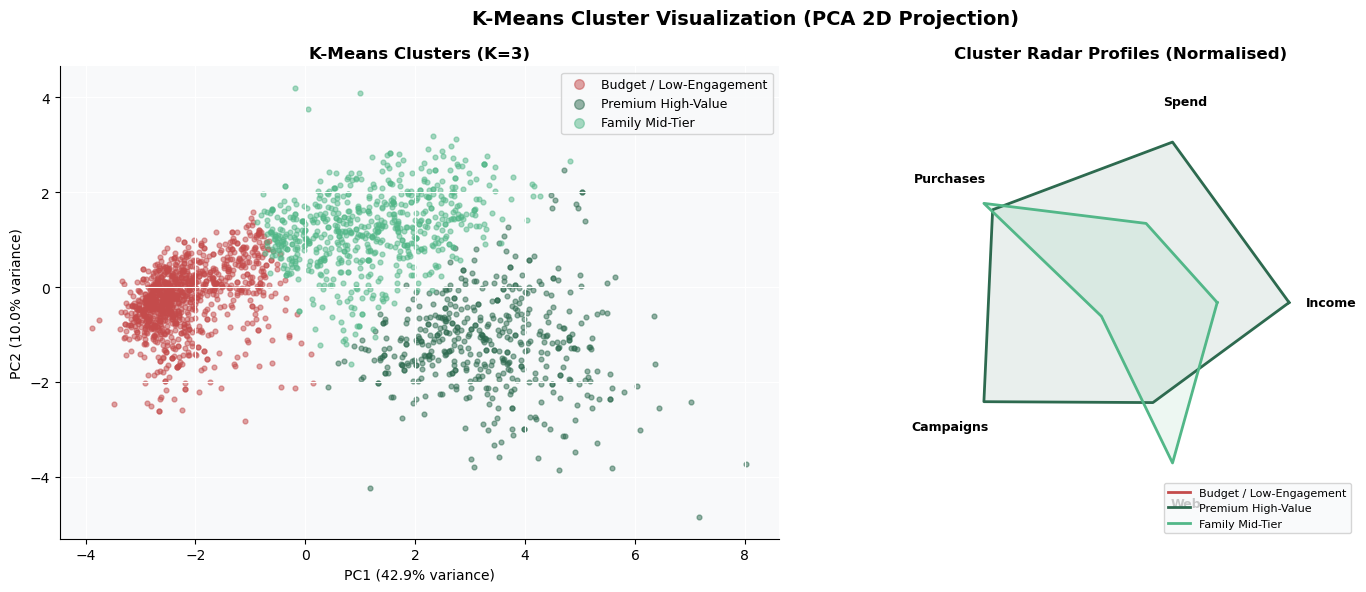

In [54]:
pca  = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)

cluster_palette = ['#C44B4B', '#52B788', '#2D6A4F']
cluster_order   = ['Budget / Low-Engagement', 'Family Mid-Tier', 'Premium High-Value']

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('K-Means Cluster Visualization (PCA 2D Projection)', fontsize=14, fontweight='bold')

for c in range(OPTIMAL_K):
    mask  = df['Cluster'] == c
    label = labels[c]
    color = cluster_palette[cluster_order.index(label)]
    axes[0].scatter(X_2d[mask, 0], X_2d[mask, 1],
                    c=color, label=label, s=12, alpha=0.5)

axes[0].set_title(f'K-Means Clusters (K={OPTIMAL_K})', fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
axes[0].legend(fontsize=9, markerscale=2)

# Radar chart
radar_metrics = ['Avg_Income', 'Avg_Spend', 'Avg_Purchases', 'Avg_Campaigns', 'Avg_Web']
radar_labels  = ['Income', 'Spend', 'Purchases', 'Campaigns', 'Web']
num_vars      = len(radar_metrics)
angles        = np.linspace(0, 2*np.pi, num_vars, endpoint=False).tolist()
angles       += angles[:1]

norm_profile = (cluster_profile[radar_metrics] - cluster_profile[radar_metrics].min()) / \
               (cluster_profile[radar_metrics].max() - cluster_profile[radar_metrics].min())

ax2 = axes[1]
ax2.set_aspect('equal')
ax2.set_xlim(-1.4, 1.4)
ax2.set_ylim(-1.4, 1.4)
ax2.axis('off')
ax2.set_title('Cluster Radar Profiles (Normalised)', fontweight='bold')

for c in range(OPTIMAL_K):
    label = labels[c]
    color = cluster_palette[cluster_order.index(label)]
    vals  = norm_profile.loc[c, radar_metrics].tolist()
    vals += vals[:1]
    xs    = [v * np.cos(a) for v, a in zip(vals, angles)]
    ys    = [v * np.sin(a) for v, a in zip(vals, angles)]
    ax2.plot(xs, ys, color=color, linewidth=2, label=label)
    ax2.fill(xs, ys, color=color, alpha=0.1)

for angle, label in zip(angles[:-1], radar_labels):
    ax2.text(1.25*np.cos(angle), 1.25*np.sin(angle), label,
             ha='center', va='center', fontsize=9, fontweight='bold')
ax2.legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.savefig('fig_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

The PCA projection confirms clear separation of Budget / Low-Engagement customers 
along PC1 (42.9% of variance), which captures the income and spend axis identified 
in the EDA. Premium High-Value and Family Mid-Tier overlap partially in the 
projection because they share similar purchase frequency -- the key differentiator 
between them is income and household composition rather than behavioral rhythm. 
The radar chart makes this explicit: Premium High-Value dominates on Income, Spend 
and Campaigns, while Family Mid-Tier matches on Purchases and Web but scores near 
zero on Campaigns, suggesting price-sensitive customers who buy regularly but do 
not respond to promotional activity.

### 4.5 RFM vs K-Means Comparison

**Do the two segmentation approaches agree?** This cross-tabulation reveals where they overlap and where K-Means captures additional signal that RFM misses, such as channel preference, campaign responsiveness and demographics.


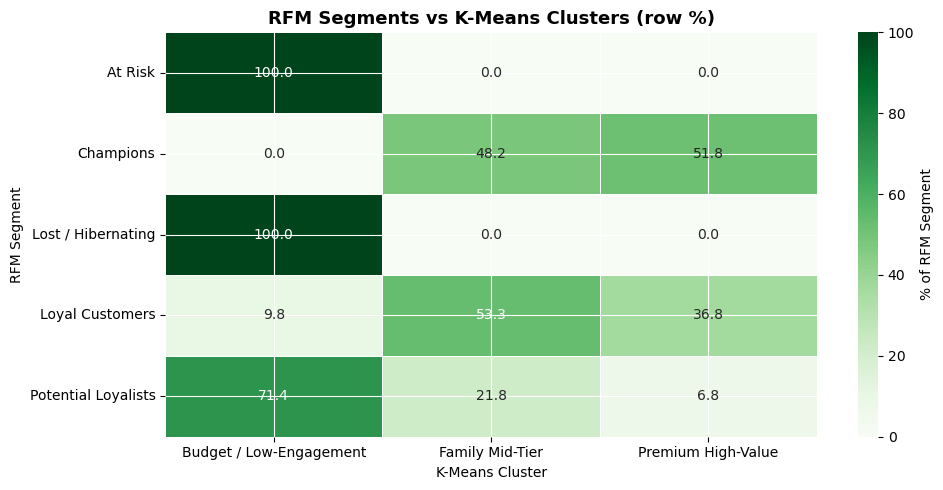

In [55]:
cross_tab = pd.crosstab(df['Segment'], df['Cluster_Label'],
                        normalize='index').round(3) * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(cross_tab, annot=True, fmt='.1f', cmap='Greens',
            linewidths=0.5, linecolor='white', ax=ax,
            cbar_kws={'label': '% of RFM Segment'})
ax.set_title('RFM Segments vs K-Means Clusters (row %)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('K-Means Cluster')
ax.set_ylabel('RFM Segment')
plt.tight_layout()
plt.savefig('fig_rfm_vs_kmeans.png', dpi=150, bbox_inches='tight')
plt.show()

- At Risk and Lost / Hibernating map entirely to Budget / Low-Engagement (100%), confirming full agreement between the two methods for the least valuable customers — low behavioral scores correspond directly to low income and spend. 
- Champions split almost equally between Family Mid-Tier (48.2%) and Premium High-Value (51.8%), revealing that RFM's best customers are demographically heterogeneous: roughly half are high-income childless customers, while the other half are family households with moderate income who compensate with high purchase frequency. 
- Loyal Customers show a similar split, with 53.3% mapping to Family Mid-Tier and 36.8% to Premium High-Value. 
- Potential Loyalists are predominantly Budget / Low-Engagement (71.4%), suggesting 
that most of this RFM segment has low income and spend potential — a signal that 
not all Potential Loyalists are worth the same investment. 

This is precisely the additional information K-Means captures that RFM misses: within the same behavioral bucket, customers can belong to structurally different demographic and economic groups, requiring differentiated communication strategies.

---
## **Communication Strategy**

The communication strategy is built directly from the analytical findings of the previous sections. Channel recommendations are derived from observed purchase behavior, message  tone is informed by campaign responsiveness scores, and targeting priorities reflect the revenue contribution analysis.


### 5.1 RFM-Segment Channel & Responsiveness Profile

We compute the key strategic dimensions for each RFM segment directly from the data: 
dominant and secondary purchase channel, campaign responsiveness, and household composition.

In [ ]:
rfm_strategy_profile = df.groupby('Segment').agg(
    N                = ('ID', 'count'),
    Avg_Recency      = ('Recency', 'mean'),
    Avg_Frequency    = ('TotalPurchases', 'mean'),
    Avg_Spend        = ('TotalSpend', 'mean'),
    Avg_Income       = ('Income', 'mean'),
    Avg_Campaigns    = ('CampaignsAccepted', 'mean'),
    Pct_Child        = ('HasChildren', 'mean'),
    Pct_Web          = ('NumWebPurchases', 'mean'),
    Pct_Store        = ('NumStorePurchases', 'mean'),
    Pct_Catalog      = ('NumCatalogPurchases', 'mean'),
).reindex(seg_order).round(2)

rfm_strategy_profile['Pct_Child'] = (rfm_strategy_profile['Pct_Child'] * 100).round(1)
rfm_strategy_profile['Dominant_Channel'] = rfm_strategy_profile[
    ['Pct_Web','Pct_Store','Pct_Catalog']
].idxmax(axis=1).map({
    'Pct_Web':     'Web',
    'Pct_Store':   'In-Store',
    'Pct_Catalog': 'Catalog'
})
rfm_strategy_profile['Secondary_Channel'] = rfm_strategy_profile[
    ['Pct_Web','Pct_Store','Pct_Catalog']
].apply(lambda x: x.nlargest(2).index[-1], axis=1).map({
    'Pct_Web':     'Web',
    'Pct_Store':   'In-Store',
    'Pct_Catalog': 'Catalog'
})

rfm_strategy_profile[['N','Avg_Recency','Avg_Frequency','Avg_Spend',
                        'Avg_Income','Avg_Campaigns','Pct_Child',
                        'Dominant_Channel','Secondary_Channel']]

,N,Avg_Recency,Avg_Frequency,Avg_Spend,Avg_Income,Avg_Campaigns,Pct_Child,Dominant_Channel,Secondary_Channel
Segment,,,,,,,,,
Champions,330,21.68,23.78,1304.84,71888.38,0.99,48.0,In-Store,Web
Loyal Customers,703,51.13,20.23,986.78,64785.06,0.62,60.0,In-Store,Web
Potential Loyalists,665,46.86,11.52,295.16,43586.36,0.26,81.0,In-Store,Web
At Risk,464,63.10,6.68,62.25,32732.23,0.12,90.0,In-Store,Web
Lost / Hibernating,70,88.17,4.91,32.63,35495.74,0.07,83.0,In-Store,Web


In-Store is the dominant channel across all five segments, with Web as the consistent 
secondary channel. Campaign responsiveness decreases monotonically from Champions 
(0.99) to Lost / Hibernating (0.07), providing a quantitative basis for calibrating 
message investment and tone across segments.

### 5.2 K-Means Cluster Channel & Responsiveness Profile

We compute the same strategic dimensions at the K-Means cluster level to enrich 
the RFM strategy with demographic and behavioral context.

In [63]:
kmeans_strategy_profile = df.groupby('Cluster_Label').agg(
    N             = ('ID', 'count'),
    Avg_Spend     = ('TotalSpend', 'mean'),
    Avg_Income    = ('Income', 'mean'),
    Avg_Campaigns = ('CampaignsAccepted', 'mean'),
    Pct_Child     = ('HasChildren', 'mean'),
    Pct_Web       = ('NumWebPurchases', 'mean'),
    Pct_Store     = ('NumStorePurchases', 'mean'),
    Pct_Catalog   = ('NumCatalogPurchases', 'mean'),
).round(2)

kmeans_strategy_profile['Pct_Child'] = (kmeans_strategy_profile['Pct_Child'] * 100).round(1)
kmeans_strategy_profile['Dominant_Channel'] = kmeans_strategy_profile[
    ['Pct_Web','Pct_Store','Pct_Catalog']
].idxmax(axis=1).map({
    'Pct_Web':     'Web',
    'Pct_Store':   'In-Store',
    'Pct_Catalog': 'Catalog'
})
kmeans_strategy_profile['Secondary_Channel'] = kmeans_strategy_profile[
    ['Pct_Web','Pct_Store','Pct_Catalog']
].apply(lambda x: x.nlargest(2).index[-1], axis=1).map({
    'Pct_Web':     'Web',
    'Pct_Store':   'In-Store',
    'Pct_Catalog': 'Catalog'
})

kmeans_strategy_profile[['N','Avg_Spend','Avg_Income',
                           'Avg_Campaigns','Pct_Child',
                           'Dominant_Channel','Secondary_Channel']]

,N,Avg_Spend,Avg_Income,Avg_Campaigns,Pct_Child,Dominant_Channel,Secondary_Channel
Cluster_Label,,,,,,,
Budget / Low-Engagement,1078,105.84,35576.19,0.17,87.0,In-Store,Web
Family Mid-Tier,679,785.05,59812.80,0.32,90.0,In-Store,Web
Premium High-Value,475,1483.38,77811.43,1.25,10.0,In-Store,Catalog


Premium High-Value customers use Catalog as their secondary channel rather than Web. This is the only segment where Catalog emerges as a relevant communication format, consistent with a high-income, low-child-percentage profile that responds to curated physical formats rather than digital promotions.

### 5.3 Cross-Segment Channel Analysis

We cross RFM segments with K-Means clusters to identify channel preferences 
at the sub-segment level, revealing where Catalog becomes strategically relevant.

In [64]:
channel_by_segment_cluster = df.groupby(['Segment', 'Cluster_Label']).agg(
    N           = ('ID', 'count'),
    Avg_Web     = ('NumWebPurchases', 'mean'),
    Avg_Store   = ('NumStorePurchases', 'mean'),
    Avg_Catalog = ('NumCatalogPurchases', 'mean'),
).round(2)

channel_by_segment_cluster['Dominant_Channel'] = channel_by_segment_cluster[
    ['Avg_Web','Avg_Store','Avg_Catalog']
].idxmax(axis=1).map({
    'Avg_Web':     'Web',
    'Avg_Store':   'In-Store',
    'Avg_Catalog': 'Catalog'
})
channel_by_segment_cluster['Secondary_Channel'] = channel_by_segment_cluster[
    ['Avg_Web','Avg_Store','Avg_Catalog']
].apply(lambda x: x.nlargest(2).index[-1], axis=1).map({
    'Avg_Web':     'Web',
    'Avg_Store':   'In-Store',
    'Avg_Catalog': 'Catalog'
})

channel_by_segment_cluster[['N','Dominant_Channel','Secondary_Channel']]

N Dominant_Channel  \
Segment             Cluster_Label                                   
At Risk             Budget / Low-Engagement  464         In-Store   
Champions           Family Mid-Tier          159         In-Store   
                    Premium High-Value       171         In-Store   
Lost / Hibernating  Budget / Low-Engagement   70         In-Store   
Loyal Customers     Budget / Low-Engagement   69         In-Store   
                    Family Mid-Tier          375         In-Store   
                    Premium High-Value       259         In-Store   
Potential Loyalists Budget / Low-Engagement  475         In-Store   
                    Family Mid-Tier          145         In-Store   
                    Premium High-Value        45         In-Store   

                                            Secondary_Channel  
Segment             Cluster_Label                              
At Risk             Budget / Low-Engagement               Web  
Champions           Family Mid-Tier                       Web  
                    Premium High-Value                Catalog  
Lost / Hibernating  Budget / Low-Engagement               Web  
Loyal Customers     Budget / Low-Engagement               Web  
                    Family Mid-Tier                       Web  
                    Premium High-Value                Catalog  
Potential Loyalists Budget / Low-Engagement               Web  
                    Family Mid-Tier                       Web  
                    Premium High-Value                Catalog

The cross-tabulation confirms that Catalog as secondary channel appears exclusively 
in combinations involving the Premium High-Value K-Means cluster: Champions × 
Premium High-Value (171 customers), Loyal Customers × Premium High-Value (259 
customers), and Potential Loyalists × Premium High-Value (45 customers). 
All other combinations default to In-Store + Web. 

This means Catalog targeting is relevant for approximately 475 customers — the entire Premium High-Value cluster — regardless of their RFM label.

### 5.4 Communication Channel Strategy

We combine the RFM and K-Means findings into a unified communication framework. 

In [65]:
strategy = pd.DataFrame([
    {
        'Segment': seg,
        'N': int(rfm_strategy_profile.loc[seg, 'N']),
        'Avg Spend ($)': round(rfm_strategy_profile.loc[seg, 'Avg_Spend'], 0),
        'Campaign Responsiveness': rfm_strategy_profile.loc[seg, 'Avg_Campaigns'],
        'Primary Channel': rfm_strategy_profile.loc[seg, 'Dominant_Channel'],
        'Secondary Channel': rfm_strategy_profile.loc[seg, 'Secondary_Channel'],
        '% With Children': rfm_strategy_profile.loc[seg, 'Pct_Child'],
    }
    for seg in seg_order
])
strategy.set_index('Segment')

,N,Avg Spend ($),Campaign Responsiveness,Primary Channel,Secondary Channel,% With Children
Segment,,,,,,
Champions,330,1305.0,0.99,In-Store,Web,48.0
Loyal Customers,703,987.0,0.62,In-Store,Web,60.0
Potential Loyalists,665,295.0,0.26,In-Store,Web,81.0
At Risk,464,62.0,0.12,In-Store,Web,90.0
Lost / Hibernating,70,33.0,0.07,In-Store,Web,83.0


- Champions and Loyal Customers account for 83.2% of total revenue and show the 
highest campaign responsiveness (0.99 and 0.62) — they warrant the highest 
communication investment via In-Store and Web. Within these two segments, 
the Premium High-Value sub-group should additionally receive Catalog communication. 

- Potential Loyalists have low responsiveness and 81% children — messaging should be value-focused and family-oriented rather than premium. 

- At Risk customers show near-zero responsiveness but represent recoverable value — a time-limited in-store offer is the most direct reactivation lever. 

- Lost / Hibernating customers (0.07 responsiveness, $33 avg spend) should receive minimal investment before being removed from active lists.

Message tone  must reflect the actual receptivity and profile of each segment. We use **campaign responsiveness** as the primary signal: high responsiveness justifies investment in elaborate, premium messaging, while low responsiveness demands simplicity and directness. **Household composition** and **income** provide a secondary layer, ensuring the tone is relevant to the customer's real context.

In [66]:
# Metrics that inform message tone
tone_inputs = rfm_strategy_profile[[
    'Avg_Campaigns', 'Pct_Child', 'Avg_Income', 'Avg_Spend'
]].reindex(seg_order)

tone_inputs.columns = [
    'Campaign Responsiveness',
    '% With Children',
    'Avg Income ($)',
    'Avg Spend ($)'
]
tone_inputs.style.background_gradient(cmap='Greens', 
    subset=['Campaign Responsiveness', 'Avg Spend ($)'])

,Campaign Responsiveness,% With Children,Avg Income ($),Avg Spend ($)
Segment,,,,
Champions,0.990000,48.000000,71888.380000,1304.840000
Loyal Customers,0.620000,60.000000,64785.060000,986.780000
Potential Loyalists,0.260000,81.000000,43586.360000,295.160000
At Risk,0.120000,90.000000,32732.230000,62.250000
Lost / Hibernating,0.070000,83.000000,35495.740000,32.630000


- Champions show the highest responsiveness and the highest income with 
only 48% children: this segment is receptive to elaborate, premium messaging. 
An exclusive and aspirational tone is appropriate, reinforcing their status as the 
company's most valuable customers.

- Loyal Customers have solid responsiveness but 60% have children and income 
is moderately lower. Messaging should be appreciative and value-oriented 
rather than purely premium, acknowledging their loyalty while offering tangible benefits.

- Potential Loyalists show low responsiveness, 81% children, and income of $43K. 
A family-friendly and benefit-focused tone is more appropriate than a premium approach:
this segment responds to relevance and practicality.

- At Risk customers have near-zero responsiveness, 90% children and the lowest 
income. The tone must be direct, urgent and simple, for example a single clear offer 
with a time limit. Elaborate messaging will not reach this group.

- Lost / Hibernating customers show minimal responsiveness with a profile similar 
to At Risk. A last-chance,  minimal-cost message is the only appropriate intervention before removing them from active communication lists.

### 5.5 High-Value Non-Responders - Trageted Intervention

We profile the hidden trend segment identified in Task B to quantify the 
communication opportunity and define a targeted intervention.

In [61]:
# High-Value Non-Responders — data-driven profile
non_resp_profile = pd.DataFrame([{
    'Segment': 'High-Value Non-Responders',
    'N': len(non_resp_hv),
    'N %': round(len(non_resp_hv)/len(df)*100, 1),
    'Avg Spend ($)': round(non_resp_hv['TotalSpend'].mean(), 0),
    'Avg Income ($)': round(non_resp_hv['Income'].mean(), 0),
    'Campaign Responsiveness': 0.0,
    'Dominant Channel': 'In-Store',
    'Spend vs Responders': f"{round((non_resp_hv['TotalSpend'].mean() / resp_hv['TotalSpend'].mean())*100, 1)}% of responder avg"
}])
non_resp_profile.set_index('Segment')

,N,N %,Avg Spend ($),Avg Income ($),Campaign Responsiveness,Dominant Channel,Spend vs Responders
Segment,,,,,,,
High-Value Non-Responders,258,11.6,1361.0,72565.0,0.0,In-Store,85.0% of responder avg


258 high-value customers (11.6% of the base) spend at 85% of the level of active 
responders ($1,361 vs $1,601) despite zero campaign responsiveness. Their income 
($72,565) is nearly identical to Champions ($71,888), ruling out purchasing power 
as the cause of non-response. 

The dominant channel is In-Store, but the absence of any campaign response suggests that current digital and promotional messaging formats are not reaching this group effectively. The recommended intervention is a Catalog-first approach with curated, 
non-promotional messaging, tested on 20% of the group via A/B test before full rollout.

---
## **Conclusions & Executive Summary**

### Overview
This analysis was conducted on a two-year retail customer dataset of 2,232 records, 
covering demographics, purchasing behavior, product spending and campaign responses. 
The business objective was to move from a one-size-fits-all communication approach 
to a **data-driven segmentation strategy** capable of targeting each customer group with the right message, through the right channel, at the right investment level.

### Analytical Approach
The analysis followed a two-layer segmentation strategy. 
- **RFM scoring** provided an interpretable behavioral framework, classifying customers based on how recently, how frequently and how much they spend. 
- **K-Means clustering** then enriched this view by incorporating demographics, channel preferences, and campaign responsiveness, revealing sub-groups within RFM buckets that require differentiated treatment.

### Key Findings

**Data Quality:** The dataset was largely clean. Eight records were removed due to 
implausible values and 24 missing income values were imputed with the median. The cleaning process was fully documented and justified.

**Spending Drivers:** **Income** is the strongest predictor of total spend (r = 0.79). 
Household composition is the most powerful non-income segmentation variable — 
customers without children spend 6x more than those with children, independently 
of income level.

**Purchase Channels:** **In-Store** dominates across all segments (39% of average 
purchases). Web visits show a slightly negative correlation with web purchases, signaling a conversion rate optimization opportunity. Catalog emerges as a relevant secondary channel exclusively for the Premium High-Value K-Means cluster.

**RFM Segmentation:** **Five segments** identified. Champions and Loyal Customers 
together represent 46.3% of customers but generate 83.2% of total revenue.

**K-Means Clustering:** **K=3** selected via data-driven criteria (Elbow + Silhouette). 
Three structurally distinct clusters identified: Premium High-Value (475 customers, 
$1,483 avg spend), Family Mid-Tier (679 customers, $785 avg spend), and Budget / 
Low-Engagement (1,078 customers, $106 avg spend). The key differentiator between 
Premium and Family clusters is income and household composition.

**Hidden Trend:** 258 high-value customers (11.6%) have never responded to any 
campaign despite spending at 85% of the level of active responders. Income and 
demographics are nearly identical to Champions, ruling out purchasing power as 
the cause. This represents an untapped revenue opportunity driven by a channel 
and message mismatch.

### Customer Value Hierarchy & Communication Strategy

| Segment | Revenue Contribution | Primary Channel | Message Tone | Priority |
|---|---|---|---|---|
| Champions | 31.9% | In-Store + Web | Exclusive & Premium | High |
| Loyal Customers | 51.3% | In-Store + Web | Appreciative & Value-focused | High |
| Potential Loyalists | 14.5% | In-Store + Web | Family-oriented & Practical | Medium |
| At Risk | 2.1% | In-Store + Web | Urgent & Direct | High — time sensitive |
| Lost / Hibernating | 0.2% | Email only | Minimal & Last-chance | Low |
| High-Value Non-Responders | -- | In-Store + Catalog | Curated & Non-promotional | High — untapped |


